In [36]:
# Instala en Colab las dependencias de esta práctica;
%pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost shap optuna scikit-optimize scipy statsmodels plotly



## Paso 0 — Imports generales


> Añadir blockquote




In [37]:
# Import generales
# %matplotlib inline

import numpy as np                          # Cálculo numérico (arreglos, medias, raíz cuadrada)
import pandas as pd                         # Manejo de datos tabulares (DataFrames)
import matplotlib.pyplot as plt             # Gráficas básicas
import seaborn as sns                       # Gráficas estadísticas (además provee datasets de este trabajo Diamonds)
import time                                 # Medir tiempos de ejecución de cada búsqueda
from scipy.stats import randint, uniform    # Distribuciones para la búsqueda aleatoria

# Opcional: silencia warnings para que la salida del notebook quede más limpia
import warnings                             # Módulo para controlar mensajes de aviso
warnings.filterwarnings('ignore')           # Oculta los warnings que no son errores




---

## Paso 1 — Descargar y cargar el dataset (Diamonds)


### Dataset elegido para esta guía: Diamonds

El dataset **Diamonds** (un clásico de Kaggle: https://www.kaggle.com/datasets/shivam2503/diamonds) es perfecto para esta actividad:

- **Objetivo de regresión**: `price` (precio del diamante en USD).
- **53.940 filas** y **10 columnas**: 6 numéricas (`carat`, `depth`, `table`, `x`, `y`, `z`) y **3 categóricas** (`cut`, `color`, `clarity`) → demuestra el preprocesamiento completo (incluido OneHotEncoder).
- NO se usó en ninguna práctica del curso.
- Es el dataset con el que se comparan los modelos de árboles en la literatura, ideal para XAI.


**Celda 2 — Carga del dataset Diamonds**


In [38]:
# Opción A (recomendada): seaborn incluye el dataset Diamonds y lo cachea localmente.
# La primera ejecución requiere internet; después queda guardado en disco.
df = sns.load_dataset('diamonds')

# Opción B (equivalente, si prefieres cumplir la parte de "descarga" literalmente):
#   1. Descarga diamonds.csv desde https://www.kaggle.com/datasets/shivam2503/diamonds
#   2. Súbelo a tu notebook y carga:
# df = pd.read_csv('diamonds.csv')   # lee el CSV local y construye el DataFrame




**Celda 3 — Primer vistazo a los datos**


In [39]:
# Muestra las primeras 5 filas para inspeccionar las columnas y sus valores
df.head()

# Dimensiones del dataset: (número de filas, número de columnas) → esperado (53940, 10)
df.shape

# Tipos de dato de cada columna y cuántos valores no nulos tiene cada una
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB




### ¿Cómo interpretar la salida?

- **Features numéricas**: `carat` (peso en quilates), `depth` (%) y `table` (%) son proporciones del tallado; `x`, `y`, `z` son las dimensiones en mm (largo, ancho, alto).
- **Features categóricas**: `cut` (calidad del corte: Fair, Good, Very Good, Premium, Ideal), `color` (escala D a J, de incoloro a amarillento), `clarity` (pureza: I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF).
- **Objetivo**: `price` en dólares (326 a 18.823, media ≈ 3.933, mediana ≈ 2.401 → distribución sesgada a la derecha; el EDA lo confirmará).
- Verifica que no haya columnas inútiles y que los tipos de dato sean los esperados (`cut`, `color`, `clarity` deben ser `object` o `category`).

---

## Paso 2 — EDA automatizado (reutilizando la Actividad 1)


### Reutilizar tu herramienta de la Actividad 1

En la Actividad 1 construiste la clase **`AutoEDA`** del módulo **`herramientas_eda.py`**, que ejecuta los **10 puntos de EDA de clase** con una sola llamada:

- `AutoEDA(df, target_col=None, figsize=(10, 6))` → constructor (recibe el DataFrame y la variable objetivo).
- `run_analysis()` → ejecuta los 10 puntos: conocer el dataset, tipo de variable, calidad de datos, valores faltantes, outliers (IQR de Tukey + boxplots), estadística descriptiva, análisis del target, análisis univariado y bivariado/multivariado (correlación de Pearson + VIF).
- `obtener_hallazgos()` → devuelve un DataFrame con la **bitácora de observaciones** 🔎 (`punto`, `tipo`, `detalle`): el insumo directo para tu interpretación.

> Principio metodológico de tu herramienta (no lo olvides al defender la práctica): **solo diagnostica y reporta**; nunca elimina filas, imputa nulos ni transforma variables automáticamente. Cada acción de limpieza es una decisión humana documentada.

**Celda 4 — Importar la clase AutoEDA de la Actividad 1**


### Módulo reutilizado desde la Actividad Integradora 1

Esta celda conserva la implementación original de `herramientas_eda.py` para que el notebook también funcione en una sesión limpia de Google Colab, donde la carpeta del repositorio no está disponible.


In [40]:
%%writefile herramientas_eda.py
# -*- coding: utf-8 -*-
"""
herramientas_eda.py — Actividad Integradora 1 · Aplicaciones de Machine Learning
================================================================================
Herramienta PROPIA de Análisis Exploratorio de Datos (EDA) 100 % automatizada,
orientada a modelos de REGRESIÓN. Cubre los 10 puntos de EDA de clase y emite un
diagnóstico estadístico, visual y de calidad de datos para detectar:

  · MULTICOLINEALIDAD  → matriz de correlación de Pearson + VIF (statsmodels).
  · SESGO (bias)       → skewness y curtosis de predictores y del target.
  · VALORES ATÍPICOS   → regla del rango intercuartílico (IQR) de Tukey + boxplots.

⚠️  PRINCIPIO METODOLÓGICO (lectura obligatoria antes de usar):
Esta clase SOLO DIAGNOSTICA Y REPORTA. Nunca elimina filas, imputa nulos ni
transforma variables de forma automática. Toda alerta estadística se presenta
como una OBSERVACIÓN (🔎) cuya acción de limpieza corresponde decidir al
analista, de forma documentada y con criterio de negocio.
"""

# ================== PASO 1. IMPORTAR LIBRERÍAS ==================
import math                                                     # módulo estándar: provee math.ceil() para calcular filas de subgráficos
import pandas as pd                                             # pandas: estructuras tabulares (DataFrame/Series) y operaciones vectorizadas
import numpy as np                                              # numpy: tipos numéricos base y funciones de álgebra/matemáticas
import matplotlib.pyplot as plt                                 # matplotlib: motor de renderizado de figuras (se usa el submódulo pyplot)
import seaborn as sns                                           # seaborn: gráficos estadísticos de alto nivel (histplot, boxplot, heatmap...)

try:                                                            # bloque tolerante: si statsmodels no está instalado, el resto de la clase sigue operativo
    from statsmodels.stats.outliers_influence import variance_inflation_factor  # statsmodels: función VIF para diagnosticar multicolinealidad
except ImportError:                                             # se captura la ausencia del paquete para degradar con elegancia (sin romper el EDA)
    variance_inflation_factor = None                            # marcador None: los métodos de VIF avisarán que el paquete no está disponible

# Constantes de los criterios estadísticos usados como umbrales de OBSERVACIÓN
UMBRAL_SKEW = 1.0      # |skewness| > 1.0  → distribución asimétrica que conviene evaluar (no transformar automáticamente)
UMBRAL_CORR = 0.80     # |r de Pearson| >= 0.80 → par de predictores con correlación lineal alta
UMBRAL_VIF_MOD = 5.0   # VIF > 5  → indicio moderado de multicolinealidad
UMBRAL_VIF_ALTO = 10.0 # VIF > 10 → indicio severo de multicolinealidad
MULTIPLO_IQR = 1.5     # factor de Tukey: Q1 - 1.5·IQR y Q3 + 1.5·IQR delimitan los valores "atípicos leves"
MULTIPLO_IQR_EXTREMO = 3.0  # factor 3.0·IQR delimita los valores "atípicos extremos"


def _mostrar(objeto):
    """Muestra un DataFrame/objeto con la representación enriquecida si está disponible (notebook) o texto plano (script)."""
    try:                                                        # intenta primero el camino interactivo de Jupyter/Colab
        from IPython.display import display                     # display() renderiza tablas HTML interactivas dentro del notebook
        display(objeto)                                         # despliega el objeto usando su representación gráfica nativa
    except ImportError:                                         # fuera de un notebook no existe IPython.display
        print(objeto)                                           # respaldo textual: print() funciona en cualquier entorno Python


class AutoEDA:
    """Clase reutilizable que ejecuta los 10 puntos de EDA de clase sobre un DataFrame, sin modificar los datos originales."""

    def __init__(self, df, target_col=None, figsize=(10, 6)):
        """Constructor: recibe el DataFrame y (opcionalmente) el nombre de la variable objetivo.

        Parámetros
        ----------
        df : pd.DataFrame
            Dataset a diagnosticar. Se trabaja sobre una COPIA para no mutar los datos del usuario.
        target_col : str, opcional
            Nombre de la variable dependiente (target). Si es numérica se asume un problema de REGRESIÓN.
        figsize : tuple, opcional
            Tamaño (ancho, alto) en pulgadas de las figuras de matplotlib.
        """
        self.df = df.copy()                                     # copia defensiva: ningún método de la clase altera el DataFrame original
        self.target_col = target_col                            # guarda el nombre del target para los análisis bivariados (puntos 8 y 10)
        self.figsize = figsize                                  # guarda el tamaño por defecto de las figuras generadas
        self.num_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()   # columnas numéricas: enteros y flotantes (incluye booleanos 0/1)
        self.cat_cols = self.df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()  # columnas categóricas/texto
        self.hallazgos = []                                     # bitácora: aquí se registran todas las OBSERVACIONES para la interpretación final

    # ----------------------------------------------------------------
    def _registrar(self, punto, tipo, detalle):
        """Registra una observación en la bitácora interna y la imprime con formato consistente.

        Parámetros
        ----------
        punto : int
            Número del punto de EDA (2 a 10) al que pertenece la observación.
        tipo : str
            Etiqueta corta de la observación (ej.: 'outliers', 'sesgo', 'multicolinealidad').
        detalle : str
            Texto explicativo con la evidencia numérica y la acción a EVALUAR (no a ejecutar).
        """
        self.hallazgos.append({'punto': punto, 'tipo': tipo, 'detalle': detalle})  # almacena la observación para el resumen final
        print(f"🔎 OBSERVACIÓN [P{punto} · {tipo}]: {detalle}")                     # imprime la observación: es un aviso, NUNCA una acción automática

    # ================== PASO 2. CONOCER EL DATASET ==================
    def _paso2_conocer_dataset(self):
        """Punto 2 — Conocer el dataset: dimensiones, memoria, catálogo de columnas y muestras (head/tail/sample)."""
        print("\n=== PASO 2. CONOCER EL DATASET ===")           # encabezado del bloque para lectura ágil del reporte
        print(f"Dimensiones: {self.df.shape[0]} filas × {self.df.shape[1]} columnas")   # .shape devuelve (n_filas, n_columnas)
        print(f"Memoria RAM estimada: {self.df.memory_usage(deep=True).sum() / 1024:.2f} KB")  # deep=True mide también los objetos internos de las cadenas
        print(f"Catálogo de columnas ({len(self.df.columns)}): {self.df.columns.tolist()}")     # .columns lista los nombres de todas las variables
        print("--- Primeras 3 filas (head) ---")                # head() inspecciona el inicio del dataset
        _mostrar(self.df.head(3))                               # muestra las 3 primeras filas para validar formato y semántica
        print("--- Últimas 3 filas (tail) ---")                 # tail() inspecciona el final (detecta registros truncados o mal cargados)
        _mostrar(self.df.tail(3))                               # muestra las 3 últimas filas
        print("--- Muestra aleatoria (sample) ---")             # sample() inspecciona filas al azar, útiles en datasets ordenados por fecha
        _mostrar(self.df.sample(3, random_state=42))            # random_state=42 fija la semilla para que la muestra sea reproducible

    # ================== PASO 3. TIPO DE VARIABLE ==================
    def _paso3_tipos_variable(self):
        """Punto 3 — Tipo de variable: clasifica cada columna (numérica vs. categórica) mediante dtypes/select_dtypes."""
        print("\n=== PASO 3. TIPO DE VARIABLE ===")             # encabezado del bloque
        tabla_tipos = pd.DataFrame({                           # construye una tabla resumen de tipos
            'tipo': self.df.dtypes.astype(str),                 # .dtypes devuelve el tipo pandas de cada columna (int64, float64, object...)
            'valores_unicos': self.df.nunique(),                # .nunique() cuenta valores distintos: útil para detectar IDs de alta cardinalidad
            'faltantes': self.df.isnull().sum(),                # conteo rápido de nulos como vista previa del punto 5
        })
        _mostrar(tabla_tipos)                                   # muestra la tabla de tipos
        print(f"Numéricas ({len(self.num_cols)}): {self.num_cols}")   # num_cols se calculó con select_dtypes(include=[np.number])
        print(f"Categóricas ({len(self.cat_cols)}): {self.cat_cols}") # cat_cols se calculó con select_dtypes(include=['object','string','category'])
        for c in self.cat_cols:                                 # recorre las categóricas buscando identificadores
            if self.df[c].nunique() == len(self.df):            # si hay tantos valores únicos como filas, la columna identifica cada registro
                self._registrar(3, 'identificador',             # registra la observación en la bitácora
                                f"'{c}' tiene {self.df[c].nunique()} valores únicos (uno por fila): "
                                f"evaluar si es un ID sin valor predictivo.")

    # ================== PASO 4. CALIDAD DE DATOS ==================
    def _paso4_calidad_datos(self):
        """Punto 4 — Calidad de datos: duplicados exactos y valores centinela ('?', '-', 'N/A', espacios sobrantes)."""
        print("\n=== PASO 4. CALIDAD DE DATOS ===")             # encabezado del bloque
        n_dup = self.df.duplicated().sum()                      # .duplicated() marca las filas idénticas a una anterior; .sum() las cuenta
        print(f"Filas duplicadas exactas: {n_dup} ({100 * n_dup / len(self.df):.2f}%)")  # porcentaje sobre el total de filas
        if n_dup > 0:                                           # solo emite observación si realmente existen duplicados
            self._registrar(4, 'duplicados',                    # registra la observación (no los elimina: decisión humana)
                            f"{n_dup} filas duplicadas detectadas: evaluar si se eliminan con "
                            f"df.drop_duplicates() o si corresponden a registros legítimos repetidos.")
        centinelas = ['?', '-', 'n/a', 'na', 'none', 'null', '']  # lista de valores típicos que "disfrazan" datos ausentes
        for c in self.cat_cols:                                 # la búsqueda de centinelas se aplica a columnas de texto
            normalizada = self.df[c].astype(str).str.strip().str.lower()  # convierte a texto, quita espacios y pasa a minúsculas para comparar
            n_raros = normalizada.isin(centinelas).sum()        # cuenta coincidencias exactas con los valores centinela
            n_espacios = (self.df[c].astype(str) != self.df[c].astype(str).str.strip()).sum()  # detecta textos con espacios al inicio o final
            if n_raros > 0 or n_espacios > 0:                   # si hay hallazgos en esta columna...
                self._registrar(4, 'valores_raros',             # ...se registra la observación con el detalle numérico
                                f"'{c}': {n_raros} valor(es) centinela ('?', '-', 'N/A'...) y "
                                f"{n_espacios} texto(s) con espacios sobrantes: evaluar normalización manual.")
            else:                                               # si la columna está limpia...
                print(f"✓ '{c}': sin valores centinela ni espacios sobrantes.")  # ...se reporta explícitamente como verificada

    # ================== PASO 5. VALORES FALTANTES ==================
    def _paso5_valores_faltantes(self):
        """Punto 5 — Valores faltantes: conteo, porcentaje y clasificación de severidad (sin imputar nada)."""
        print("\n=== PASO 5. VALORES FALTANTES ===")            # encabezado del bloque
        nulos = self.df.isnull().sum()                          # .isnull() marca cada celda vacía; .sum() cuenta los nulos por columna
        pct = (nulos / len(self.df)) * 100                      # convierte el conteo a porcentaje sobre el total de filas
        tabla_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje(%)': pct.round(2)})  # tabla resumen ordenable por severidad
        _mostrar(tabla_nulos)                                   # muestra la tabla completa de nulos
        for c in self.df.columns:                               # recorre todas las columnas del dataset
            if nulos[c] > 0:                                    # solo clasifica las columnas que tienen nulos
                if pct[c] < 5:                                  # umbral 1: menos del 5 % de nulos
                    severidad = 'baja → evaluar imputación simple (media/mediana/moda)'
                elif pct[c] <= 30:                              # umbral 2: entre 5 % y 30 % de nulos
                    severidad = 'media → evaluar imputación avanzada o modelado específico'
                else:                                           # más del 30 % de nulos
                    severidad = 'alta → evaluar descarte de la columna o tratamiento especial'
                self._registrar(5, 'nulos',                     # registra la observación indicando severidad y opciones a EVALUAR
                                f"'{c}': {nulos[c]} nulos ({pct[c]:.2f}%) → severidad {severidad}. "
                                f"La herramienta NO imputa: la estrategia la define el analista.")
        if nulos.sum() == 0:                                    # caso más frecuente en datasets limpios
            print("✓ No se detectaron valores nulos (NaN/None): no se requiere estrategia de imputación.")  # confirma la ausencia de nulos

    # ================== PASO 6. OUTLIERS ==================
    def _paso6_outliers(self):
        """Punto 6 — Outliers: regla del IQR de Tukey (1.5× y 3.0×) sobre cada variable numérica + boxplots."""
        print("\n=== PASO 6. OUTLIERS (REGLA DEL IQR) ===")     # encabezado del bloque
        filas = []                                              # acumulador de resúmenes por variable
        for c in self.num_cols:                                 # la regla del IQR solo aplica a variables numéricas
            q1 = self.df[c].quantile(0.25)                      # primer cuartil Q1: valor bajo el cual queda el 25 % de los datos
            q3 = self.df[c].quantile(0.75)                      # tercer cuartil Q3: valor bajo el cual queda el 75 % de los datos
            iqr = q3 - q1                                       # rango intercuartílico: dispersión del 50 % central
            lim_inf = q1 - MULTIPLO_IQR * iqr                   # límite inferior de Tukey (1.5 × IQR)
            lim_sup = q3 + MULTIPLO_IQR * iqr                   # límite superior de Tukey (1.5 × IQR)
            n_out = ((self.df[c] < lim_inf) | (self.df[c] > lim_sup)).sum()   # cuenta valores fuera del intervalo [lim_inf, lim_sup]
            n_ext = ((self.df[c] < q1 - MULTIPLO_IQR_EXTREMO * iqr) |        # umbral 3.0 × IQR para atípicos extremos
                     (self.df[c] > q3 + MULTIPLO_IQR_EXTREMO * iqr)).sum()
            filas.append({'variable': c, 'Q1': round(q1, 2), 'Q3': round(q3, 2), 'IQR': round(iqr, 2),
                          'atipicos': n_out, 'atipicos_%': round(100 * n_out / len(self.df), 2),
                          'extremos': n_ext})                    # agrega el resumen de la variable a la lista
            if n_out > 0:                                       # emite observación solo si la variable tiene atípicos
                self._registrar(6, 'outliers',                  # registra la observación: sugiere VERIFICAR, nunca borrar
                                f"'{c}': {n_out} valores atípicos ({100 * n_out / len(self.df):.2f}%) y {n_ext} extremos. "
                                f"Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.")
        _mostrar(pd.DataFrame(filas))                           # muestra la tabla resumen de outliers
        ncols = 3                                               # número de boxplots por fila en la cuadrícula
        nrows = math.ceil(len(self.num_cols) / ncols)           # calcula cuántas filas de subgráficos se necesitan
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))  # crea la cuadrícula de ejes
        axes = axes.flatten()                                   # convierte la matriz de ejes en lista plana para iterar fácil
        for i, c in enumerate(self.num_cols):                   # recorre cada variable numérica con su subgráfico
            sns.boxplot(data=self.df, x=c, ax=axes[i])          # boxplot horizontal: mediana, caja Q1–Q3, bigotes y puntos atípicos
            axes[i].set_title(f'Boxplot de {c}')                # titula el subgráfico con el nombre de la variable
        for j in range(len(self.num_cols), len(axes)):          # recorre los ejes sobrantes (si sobran celdas en la cuadrícula)
            axes[j].axis('off')                                 # apaga los ejes vacíos para una figura limpia
        plt.tight_layout()                                      # ajusta márgenes para que títulos y etiquetas no se solapen
        plt.show()                                              # renderiza la figura (en notebook: salida en línea; en script: ventana/archivo)

    # ================== PASO 7. ESTADÍSTICA DESCRIPTIVA ==================
    def _paso7_estadistica_descriptiva(self):
        """Punto 7 — Estadística descriptiva: tendencia central, dispersión, asimetría y curtosis de las numéricas."""
        print("\n=== PASO 7. ESTADÍSTICA DESCRIPTIVA ===")      # encabezado del bloque
        if not self.num_cols:                                   # si no hay variables numéricas no hay nada que describir
            print("⚠ No hay variables numéricas en el dataset.")  # aviso explícito en lugar de fallar
            return                                              # termina el método sin error
        desc = self.df[self.num_cols].describe().T              # describe() calcula count, mean, std, min, cuartiles y max; .T transpone
        desc['rango'] = desc['max'] - desc['min']               # amplitud total: distancia entre el máximo y el mínimo
        desc['cv'] = desc.apply(                                # coeficiente de variación CV = std/media (dispersión relativa)
            lambda fila: (fila['std'] / fila['mean']) if fila['mean'] != 0 else np.nan,  # evita dividir entre cero cuando media=0
            axis=1).round(2)                                    # axis=1 aplica la función fila por fila; .round(2) limita decimales
        desc['skewness'] = self.df[self.num_cols].skew().round(2)   # skew(): asimetría muestral (>0 cola derecha, <0 cola izquierda)
        desc['curtosis'] = self.df[self.num_cols].kurt().round(2)   # kurt(): curtosis EXCESIVA (0 = normal; >0 colas pesadas)
        _mostrar(desc[['mean', 'std', 'min', '50%', 'max', 'rango', 'cv', 'skewness', 'curtosis']])  # muestra las columnas relevantes
        print("· '50%' es la mediana (percentil 50): si difiere mucho de la media, la distribución está sesgada.")  # ayuda interpretativa

    # ================== PASO 8. DESBALANCE / TARGET ==================
    def _paso8_target(self):
        """Punto 8 — Variable objetivo: distribución (regresión, target continuo) o balance de clases (clasificación)."""
        print("\n=== PASO 8. VARIABLE OBJETIVO (TARGET) ===")   # encabezado del bloque
        if self.target_col is None:                             # la clase también debe funcionar sin target (análisis exploratorio puro)
            print("ℹ No se declaró target_col: se omite el punto 8 (pasar target_col='nombre' al instanciar).")
            return                                              # termina el método sin error
        if self.target_col not in self.df.columns:              # valida que el nombre del target exista realmente en el DataFrame
            print(f"⚠ El target '{self.target_col}' no existe entre las columnas: {self.df.columns.tolist()}")
            return                                              # termina el método sin error
        if self.target_col in self.num_cols:                    # RAMA REGRESIÓN: el target es continuo
            s = self.df[self.target_col]                        # Serie con los valores del target
            print(f"Target continuo '{self.target_col}': media={s.mean():.2f} · mediana={s.median():.2f} · "
                  f"min={s.min():.2f} · max={s.max():.2f} · skew={s.skew():.2f}")  # resumen de forma y ubicación
            if abs(s.skew()) > UMBRAL_SKEW:                     # compara la asimetría con el umbral de observación
                self._registrar(8, 'sesgo_target',              # registra la observación sobre el target
                                f"El target '{self.target_col}' tiene |skew|={abs(s.skew()):.2f} > {UMBRAL_SKEW}: "
                                f"la media se aleja de la mediana. Evaluar transformación log(1+x) o Box-Cox "
                                f"SOLO si el modelo lo requiere (decisión humana, no automática).")
            plt.figure(figsize=self.figsize)                    # crea una figura nueva con el tamaño por defecto
            sns.histplot(s, kde=True, bins=30)                  # histograma con curva de densidad KDE: revela la forma de la distribución
            plt.axvline(s.mean(), color='red', linestyle='--', label=f'media={s.mean():.0f}')    # línea vertical en la media
            plt.axvline(s.median(), color='green', linestyle='--', label=f'mediana={s.median():.0f}')  # línea vertical en la mediana
            plt.title(f'Distribución del target: {self.target_col}')  # título descriptivo de la figura
            plt.legend()                                        # muestra la leyenda con media y mediana
            plt.show()                                          # renderiza la figura
        else:                                                   # RAMA CLASIFICACIÓN: el target es categórico
            conteos = self.df[self.target_col].value_counts(normalize=True) * 100  # value_counts(normalize=True) devuelve proporciones por clase
            print(f"Distribución de clases del target '{self.target_col}' (%):")  # encabezado de la tabla de balance
            _mostrar(conteos.round(2))                          # muestra los porcentajes de cada clase
            if conteos.min() < 20:                              # regla práctica: clase minoritaria por debajo del 20 % = desbalance
                self._registrar(8, 'desbalance',                # registra la observación de desbalance
                                f"La clase minoritaria '{conteos.idxmin()}' representa {conteos.min():.1f}%: "
                                f"evaluar técnicas de balanceo (SMOTE, class_weight) según el modelo elegido.")
            plt.figure(figsize=self.figsize)                    # crea la figura
            sns.countplot(data=self.df, x=self.target_col)      # countplot: barras con la frecuencia de cada clase
            plt.title(f'Balance de clases: {self.target_col}')  # título de la figura
            plt.show()                                          # renderiza la figura

    # ================== PASO 9. ANÁLISIS UNIVARIADO ==================
    def _paso9_analisis_univariado(self):
        """Punto 9 — Análisis univariado: histogramas + KDE y diagnóstico de sesgo (skewness) y curtosis por variable."""
        print("\n=== PASO 9. ANÁLISIS UNIVARIADO (DISTRIBUCIONES) ===")  # encabezado del bloque
        if not self.num_cols:                                   # guarda: sin numéricas no aplica
            print("⚠ No hay variables numéricas en el dataset.")
            return                                              # termina el método sin error
        tabla_forma = pd.DataFrame({                           # tabla comparativa de forma de cada distribución
            'skewness': self.df[self.num_cols].skew().round(2),     # asimetría por variable
            'curtosis': self.df[self.num_cols].kurt().round(2),     # curtosis excesiva por variable
        })
        _mostrar(tabla_forma)                                   # muestra la tabla de forma
        for c in self.num_cols:                                 # recorre cada variable numérica
            if abs(tabla_forma.loc[c, 'skewness']) > UMBRAL_SKEW:  # aplica el umbral de sesgo severo
                self._registrar(9, 'sesgo',                     # registra la observación de asimetría
                                f"'{c}': |skew|={abs(tabla_forma.loc[c, 'skewness']):.2f} > {UMBRAL_SKEW} → "
                                f"distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: "
                                f"no es una acción automática.")
        ncols = 3                                               # número de histogramas por fila
        nrows = math.ceil(len(self.num_cols) / ncols)           # filas necesarias de la cuadrícula
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))  # crea la cuadrícula de ejes
        axes = axes.flatten()                                   # aplana los ejes para iterar
        for i, c in enumerate(self.num_cols):                   # recorre cada variable con su subgráfico
            sns.histplot(self.df[c], kde=True, bins=30, ax=axes[i], color='skyblue')  # histograma + curva KDE de la variable
            axes[i].set_title(f'Distribución de {c} (skew={tabla_forma.loc[c, "skewness"]})')  # título con la asimetría
        for j in range(len(self.num_cols), len(axes)):          # apaga ejes sobrantes
            axes[j].axis('off')                                 # oculta celdas vacías de la cuadrícula
        plt.tight_layout()                                      # ajusta márgenes
        plt.show()                                              # renderiza la figura

    # ================== PASO 10. BIVARIADO / MULTIVARIADO ==================
    def _paso10_bivariado_multivariado(self):
        """Punto 10 — Bivariado/multivariado: relación con el target, correlación (heatmap) y multicolinealidad (VIF)."""
        print("\n=== PASO 10. ANÁLISIS BIVARIADO Y MULTIVARIADO ===")  # encabezado del bloque
        # --- 10a. Predictores NUMÉRICOS vs target: scatter con recta de tendencia ---
        if self.target_col and self.target_col in self.num_cols:  # solo aplica si hay target numérico declarado
            corr_target = self.df[self.num_cols].corr()[self.target_col].drop(self.target_col)  # correlación Pearson de cada numérica con el target
            corr_target = corr_target.sort_values(key=abs, ascending=False)  # ordena por valor absoluto: las más influyentes primero
            print(f"Correlación de Pearson de cada predictor numérico con '{self.target_col}':")  # encabezado del ranking
            _mostrar(corr_target.round(3))                      # muestra el ranking de correlaciones con el target
            for c in [x for x in self.num_cols if x != self.target_col]:  # recorre los predictores numéricos (excluye el target)
                plt.figure(figsize=self.figsize)                # figura por cada relación predictor–target
                sns.regplot(data=self.df, x=c, y=self.target_col,  # regplot: nube de puntos + recta de regresión lineal
                            scatter_kws={'alpha': 0.35},        # transparencia de los puntos para ver densidad
                            line_kws={'color': 'red'})          # recta de tendencia en rojo
                plt.title(f'{c} vs {self.target_col} (r={corr_target[c]:.3f})')  # título con el coeficiente de Pearson
                plt.show()                                      # renderiza la figura
        # --- 10b. Predictores CATEGÓRICOS vs target: boxplots agrupados ---
        if self.target_col and self.target_col in self.df.columns:  # aplica a cualquier target declarado (numérico o categórico)
            for c in self.cat_cols:                             # recorre cada variable categórica
                plt.figure(figsize=self.figsize)                # figura por categoría
                sns.boxplot(data=self.df, x=c, y=self.target_col)  # boxplot del target por cada categoría: revela efectos de grupo
                plt.title(f'{self.target_col} por {c}')         # título descriptivo
                plt.show()                                      # renderiza la figura
        # --- 10c. Matriz de correlación (heatmap) y pares colineales ---
        if len(self.num_cols) > 1:                              # se necesitan al menos 2 numéricas para correlacionar
            corr = self.df[self.num_cols].corr()                # matriz de correlación lineal de Pearson entre todas las numéricas
            plt.figure(figsize=(8, 6))                          # figura cuadrada para el heatmap
            sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',  # heatmap anotado: color frío para negativos, cálido para positivos
                        center=0, linewidths=0.5)               # center=0 ancla la escala de color en correlación nula
            plt.title('Matriz de correlación de Pearson (variables numéricas)')  # título del heatmap
            plt.tight_layout()                                  # ajusta márgenes
            plt.show()                                          # renderiza el heatmap
            for i in range(len(self.num_cols)):                 # doble bucle para revisar TODOS los pares sin repetir
                for j in range(i + 1, len(self.num_cols)):      # j inicia en i+1: solo la mitad triangular superior
                    v = corr.iloc[i, j]                         # coeficiente del par (i, j)
                    if abs(v) >= UMBRAL_CORR:                   # aplica el umbral de alta correlación
                        self._registrar(10, 'multicolinealidad',  # registra el par colineal como observación
                                        f"'{self.num_cols[i]}' y '{self.num_cols[j]}' con |r|={abs(v):.2f} ≥ {UMBRAL_CORR}: "
                                        f"evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.")
            if not any(abs(corr.iloc[i, j]) >= UMBRAL_CORR      # verifica si NO hubo ningún par por encima del umbral
                       for i in range(len(self.num_cols)) for j in range(i + 1, len(self.num_cols))):
                print(f"✓ Ningún par de variables numéricas supera |r| = {UMBRAL_CORR}.")  # confirma ausencia de correlación extrema
        # --- 10d. VIF: Factor de Inflación de la Varianza ---
        if variance_inflation_factor is None:                   # si statsmodels no se instaló en el entorno...
            print("⚠ VIF no disponible: instala statsmodels (pip install statsmodels) para el diagnóstico de multicolinealidad.")
            return                                              # termina solo este bloque, no el resto del análisis
        predictores = [c for c in self.num_cols if c != self.target_col]  # excluye el target del cálculo de VIF
        if len(predictores) > 1:                                # el VIF exige al menos 2 predictores
            X = self.df[predictores].dropna()                   # VIF requiere matriz sin nulos ni constantes; dropna garantiza lo primero
            try:                                                # protege contra columnas constantes (varianza cero) que invalidan el VIF
                tabla_vif = pd.DataFrame({                      # construye la tabla de resultados
                    'variable': predictores,                    # nombre de cada predictor
                    'VIF': [round(variance_inflation_factor(X.values, i), 2) for i in range(len(predictores))],  # VIF_i = 1/(1-R²_i) de cada predictor frente a los demás
                })
                _mostrar(tabla_vif)                             # muestra la tabla VIF
                for i, c in enumerate(predictores):             # recorre los resultados para clasificar la severidad
                    if tabla_vif.loc[i, 'VIF'] > UMBRAL_VIF_ALTO:      # VIF > 10: multicolinealidad severa
                        self._registrar(10, 'vif',              # registra la observación severa
                                        f"'{c}': VIF={tabla_vif.loc[i, 'VIF']:.2f} > {UMBRAL_VIF_ALTO} → multicolinealidad severa: "
                                        f"evaluar eliminar la variable o combinarla con otra.")
                    elif tabla_vif.loc[i, 'VIF'] > UMBRAL_VIF_MOD:     # VIF entre 5 y 10: multicolinealidad moderada
                        self._registrar(10, 'vif',              # registra la observación moderada
                                        f"'{c}': VIF={tabla_vif.loc[i, 'VIF']:.2f} > {UMBRAL_VIF_MOD} → multicolinealidad moderada: "
                                        f"monitorear su efecto sobre los coeficientes del modelo.")
                if (tabla_vif['VIF'] <= UMBRAL_VIF_MOD).all():  # si todos los VIF quedan por debajo del umbral moderado
                    print(f"✓ VIF de todos los predictores ≤ {UMBRAL_VIF_MOD}: sin indicios de multicolinealidad.")  # confirma diagnóstico sano
            except ValueError:                                  # captura el caso de columnas constantes u otros fallos numéricos
                print("⚠ No se pudo calcular el VIF (posible columna constante o singularidad numérica).")  # aviso sin romper el flujo

    # ================== ORQUESTADOR PRINCIPAL ==================
    def run_analysis(self):
        """Método público: ejecuta los 10 puntos de EDA en orden y de forma 100 % automatizada (una sola llamada)."""
        print("=" * 72)                                         # línea separadora superior del reporte
        print(" DIAGNÓSTICO AUTOMATIZADO DE EDA · ORIENTADO A REGRESIÓN ".center(72))  # título centrado del reporte
        print("=" * 72)                                         # línea separadora
        print("⚠  Esta herramienta SOLO diagnostica y reporta: no elimina filas, no imputa")
        print("   nulos y no transforma variables. Cada acción de limpieza es una decisión")
        print("   HUMANA que debe documentarse en la sección de interpretación.\n")
        print("PASO 1 (importar librerías) se cumple en la cabecera de este módulo:")  # aclaración del punto 1
        print("pandas, numpy, matplotlib, seaborn y statsmodels (para el VIF).\n")
        self._paso2_conocer_dataset()                           # ejecuta el punto 2: conocer el dataset
        self._paso3_tipos_variable()                            # ejecuta el punto 3: tipo de variable
        self._paso4_calidad_datos()                             # ejecuta el punto 4: calidad de datos
        self._paso5_valores_faltantes()                         # ejecuta el punto 5: valores faltantes
        self._paso6_outliers()                                  # ejecuta el punto 6: outliers (IQR + boxplots)
        self._paso7_estadistica_descriptiva()                   # ejecuta el punto 7: estadística descriptiva
        self._paso8_target()                                    # ejecuta el punto 8: target / balance de clases
        self._paso9_analisis_univariado()                       # ejecuta el punto 9: análisis univariado
        self._paso10_bivariado_multivariado()                   # ejecuta el punto 10: bivariado/multivariado + VIF
        print("=" * 72)                                         # línea separadora inferior
        print(f" DIAGNÓSTICO COMPLETADO · {len(self.hallazgos)} observaciones registradas ".center(72))  # total de observaciones
        print("=" * 72)                                         # línea separadora
        print("Para la interpretación final ejecuta: eda.obtener_hallazgos()")  # indica cómo recuperar la bitácora

    def obtener_hallazgos(self):
        """Devuelve la bitácora completa de observaciones como DataFrame, insumo para la sección de interpretación."""
        if not self.hallazgos:                                  # caso sin observaciones registradas
            return pd.DataFrame(columns=['punto', 'tipo', 'detalle'])  # devuelve la tabla vacía con las mismas columnas
        return pd.DataFrame(self.hallazgos)                     # convierte la lista de dictados en un DataFrame tabular


Overwriting herramientas_eda.py


In [41]:
# Importamos rutas para reutilizar el módulo de la Actividad 1 si está en la carpeta hermana.
from pathlib import Path
import sys

# Buscamos la carpeta local de la Actividad 1 tanto desde el repositorio como desde la carpeta del notebook.
rutas_actividad_1 = [Path.cwd() / "Actividad Integradora 1", Path.cwd().parent / "Actividad Integradora 1"]
for ruta in rutas_actividad_1:
    if (ruta / "herramientas_eda.py").exists():
        sys.path.insert(0, str(ruta))
        break

# Importamos la clase AutoEDA reutilizada de la Actividad 1; en Colab la celda anterior la crea desde este notebook.
from herramientas_eda import AutoEDA




**Celda 5 — Ejecutar el EDA automatizado sobre Diamonds**


        DIAGNÓSTICO AUTOMATIZADO DE EDA · ORIENTADO A REGRESIÓN         
⚠  Esta herramienta SOLO diagnostica y reporta: no elimina filas, no imputa
   nulos y no transforma variables. Cada acción de limpieza es una decisión
   HUMANA que debe documentarse en la sección de interpretación.

PASO 1 (importar librerías) se cumple en la cabecera de este módulo:
pandas, numpy, matplotlib, seaborn y statsmodels (para el VIF).


=== PASO 2. CONOCER EL DATASET ===
Dimensiones: 53940 filas × 10 columnas
Memoria RAM estimada: 3109.77 KB
Catálogo de columnas (10): ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']
--- Primeras 3 filas (head) ---


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31


--- Últimas 3 filas (tail) ---


,carat,cut,color,clarity,depth,table,price,x,y,z
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


--- Muestra aleatoria (sample) ---


,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95


... (2 outputs left out)

Numéricas (7): ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Categóricas (3): ['cut', 'color', 'clarity']

=== PASO 4. CALIDAD DE DATOS ===
Filas duplicadas exactas: 146 (0.27%)
🔎 OBSERVACIÓN [P4 · duplicados]: 146 filas duplicadas detectadas: evaluar si se eliminan con df.drop_duplicates() o si corresponden a registros legítimos repetidos.
✓ 'cut': sin valores centinela ni espacios sobrantes.
✓ 'color': sin valores centinela ni espacios sobrantes.
✓ 'clarity': sin valores centinela ni espacios sobrantes.

=== PASO 5. VALORES FALTANTES ===


,nulos,porcentaje(%)
carat,0,0.0
cut,0,0.0
color,0,0.0
clarity,0,0.0
depth,0,0.0
table,0,0.0
price,0,0.0
x,0,0.0
y,0,0.0
z,0,0.0


✓ No se detectaron valores nulos (NaN/None): no se requiere estrategia de imputación.

=== PASO 6. OUTLIERS (REGLA DEL IQR) ===
🔎 OBSERVACIÓN [P6 · outliers]: 'carat': 1889 valores atípicos (3.50%) y 40 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN [P6 · outliers]: 'depth': 2545 valores atípicos (4.72%) y 278 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN [P6 · outliers]: 'table': 605 valores atípicos (1.12%) y 28 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN [P6 · outliers]: 'price': 3540 valores atípicos (6.56%) y 120 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN [P6 · outliers]: 'x': 32 valores atípicos (0.06%) y 0 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN

,variable,Q1,Q3,IQR,atipicos,atipicos_%,extremos
0,carat,0.40,1.04,0.64,1889,3.50,40
1,depth,61.00,62.50,1.50,2545,4.72,278
2,table,56.00,59.00,3.00,605,1.12,28
3,price,950.00,5324.25,4374.25,3540,6.56,120
4,x,4.71,6.54,1.83,32,0.06,0
5,y,4.72,6.54,1.82,29,0.05,2
6,z,2.91,4.04,1.13,49,0.09,2


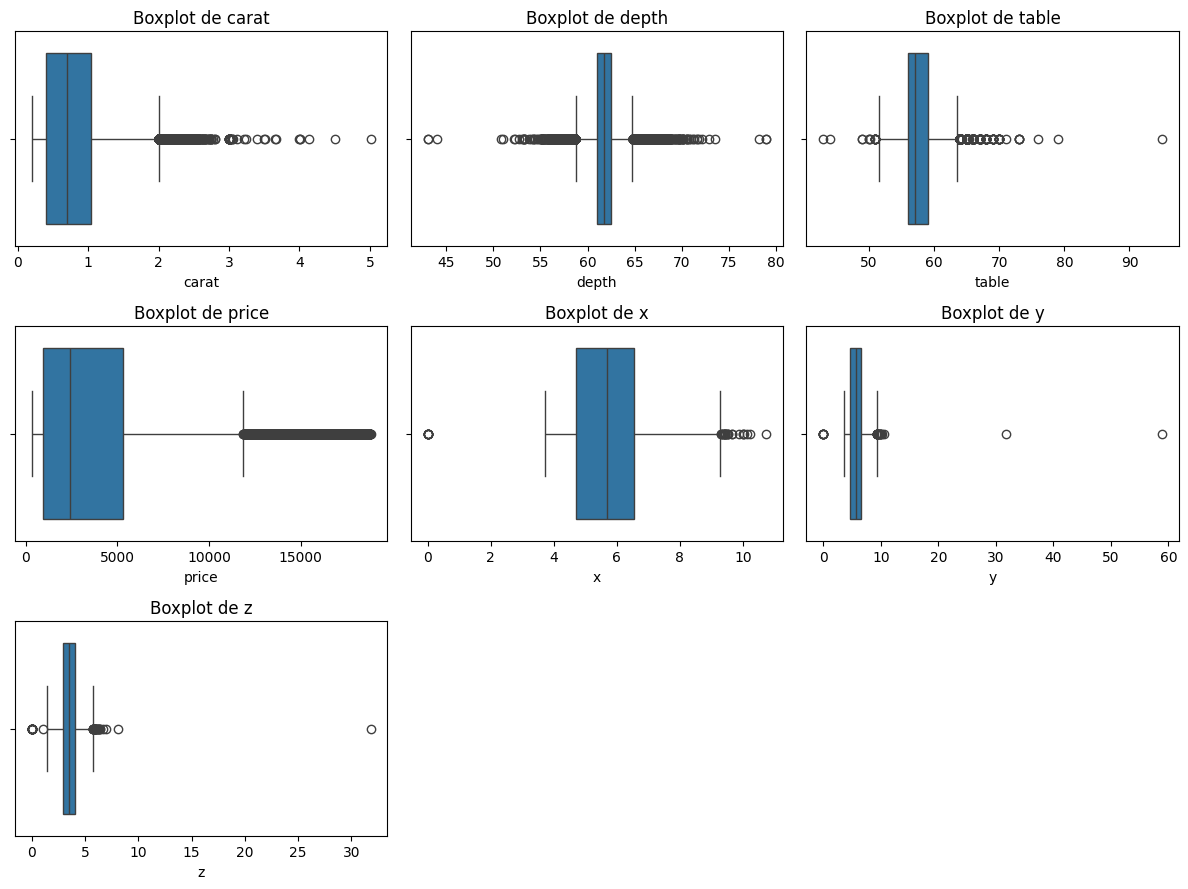


=== PASO 7. ESTADÍSTICA DESCRIPTIVA ===


,mean,std,min,50%,max,rango,cv,skewness,curtosis
carat,0.797940,0.474011,0.2,0.70,5.01,4.81,0.59,1.12,1.26
depth,61.749405,1.432621,43.0,61.80,79.00,36.00,0.02,-0.08,5.74
table,57.457184,2.234491,43.0,57.00,95.00,52.00,0.04,0.80,2.80
price,3932.799722,3989.439738,326.0,2401.00,18823.00,18497.00,1.01,1.62,2.18
x,5.731157,1.121761,0.0,5.70,10.74,10.74,0.20,0.38,-0.62
y,5.734526,1.142135,0.0,5.71,58.90,58.90,0.20,2.43,91.21
z,3.538734,0.705699,0.0,3.53,31.80,31.80,0.20,1.52,47.09


· '50%' es la mediana (percentil 50): si difiere mucho de la media, la distribución está sesgada.

=== PASO 8. VARIABLE OBJETIVO (TARGET) ===
Target continuo 'price': media=3932.80 · mediana=2401.00 · min=326.00 · max=18823.00 · skew=1.62
🔎 OBSERVACIÓN [P8 · sesgo_target]: El target 'price' tiene |skew|=1.62 > 1.0: la media se aleja de la mediana. Evaluar transformación log(1+x) o Box-Cox SOLO si el modelo lo requiere (decisión humana, no automática).


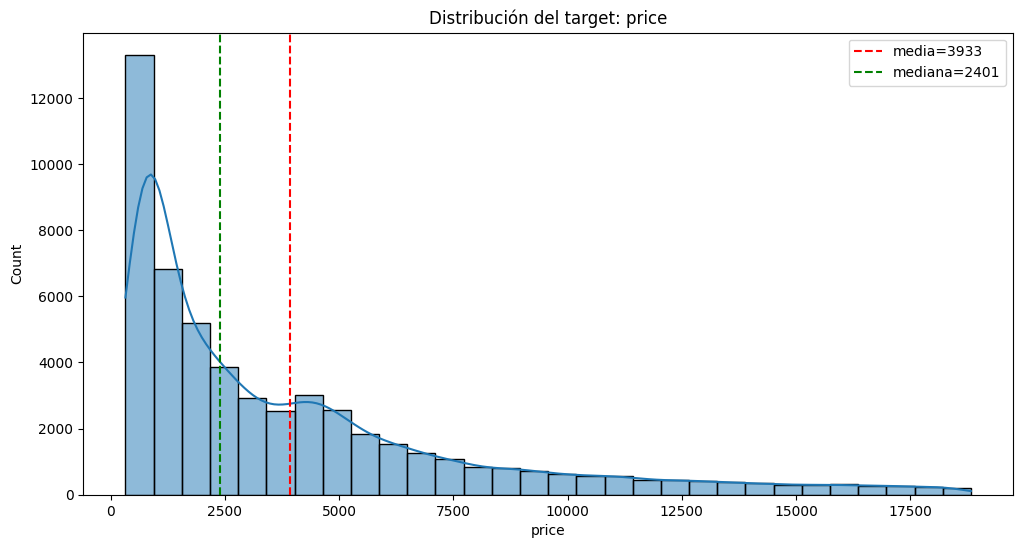


=== PASO 9. ANÁLISIS UNIVARIADO (DISTRIBUCIONES) ===


,skewness,curtosis
carat,1.12,1.26
depth,-0.08,5.74
table,0.80,2.80
price,1.62,2.18
x,0.38,-0.62
y,2.43,91.21
z,1.52,47.09


🔎 OBSERVACIÓN [P9 · sesgo]: 'carat': |skew|=1.12 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.
🔎 OBSERVACIÓN [P9 · sesgo]: 'price': |skew|=1.62 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.
🔎 OBSERVACIÓN [P9 · sesgo]: 'y': |skew|=2.43 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.
🔎 OBSERVACIÓN [P9 · sesgo]: 'z': |skew|=1.52 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.


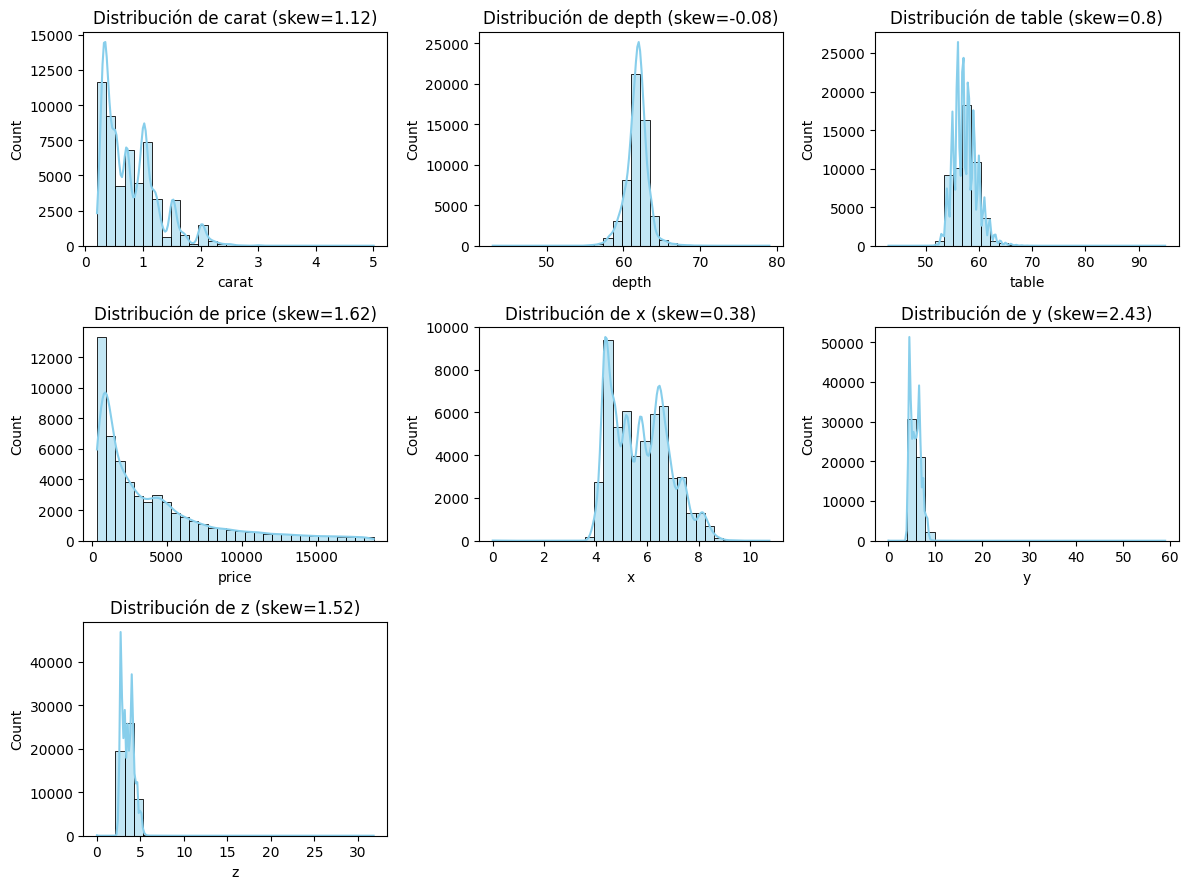


=== PASO 10. ANÁLISIS BIVARIADO Y MULTIVARIADO ===
Correlación de Pearson de cada predictor numérico con 'price':


,price
carat,0.922
x,0.884
y,0.865
z,0.861
table,0.127
depth,-0.011


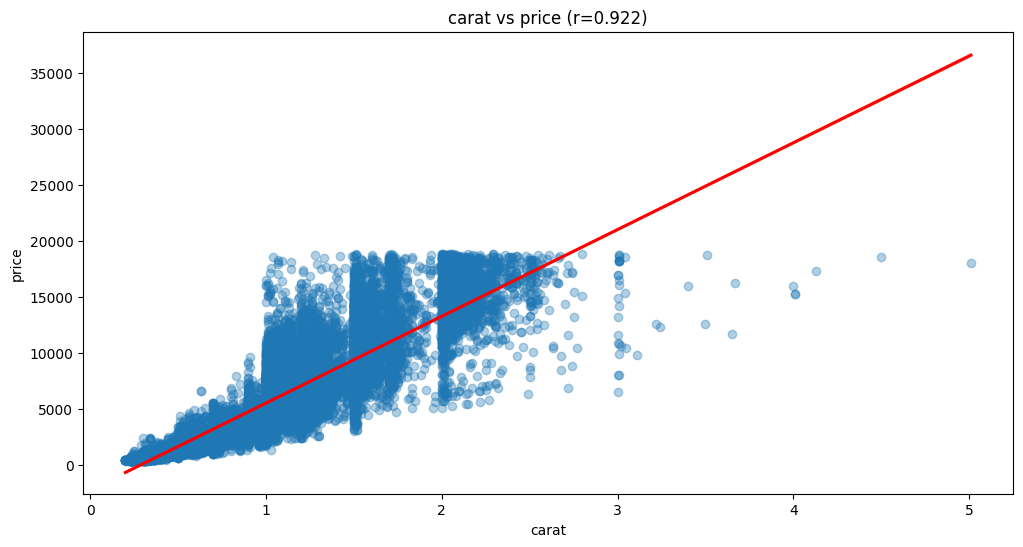

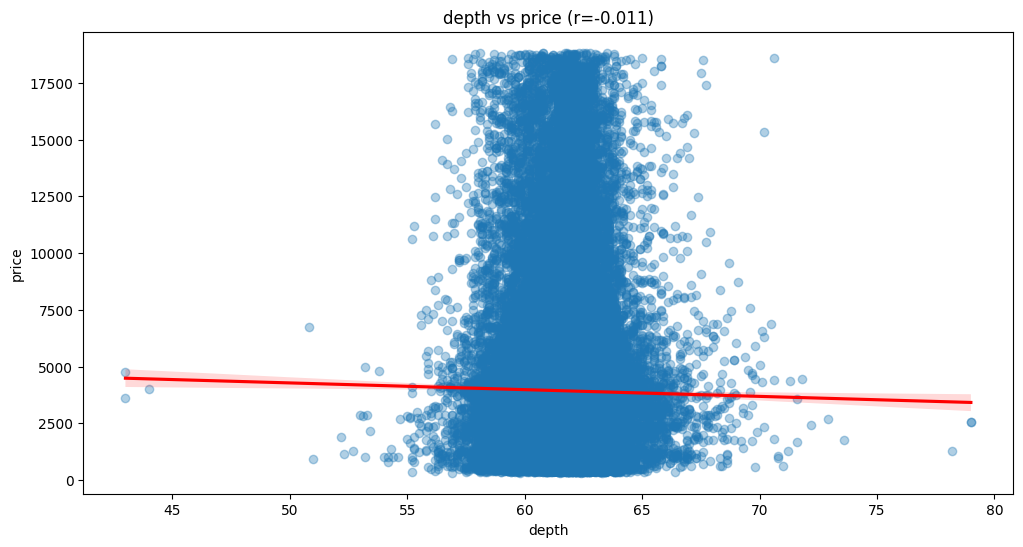

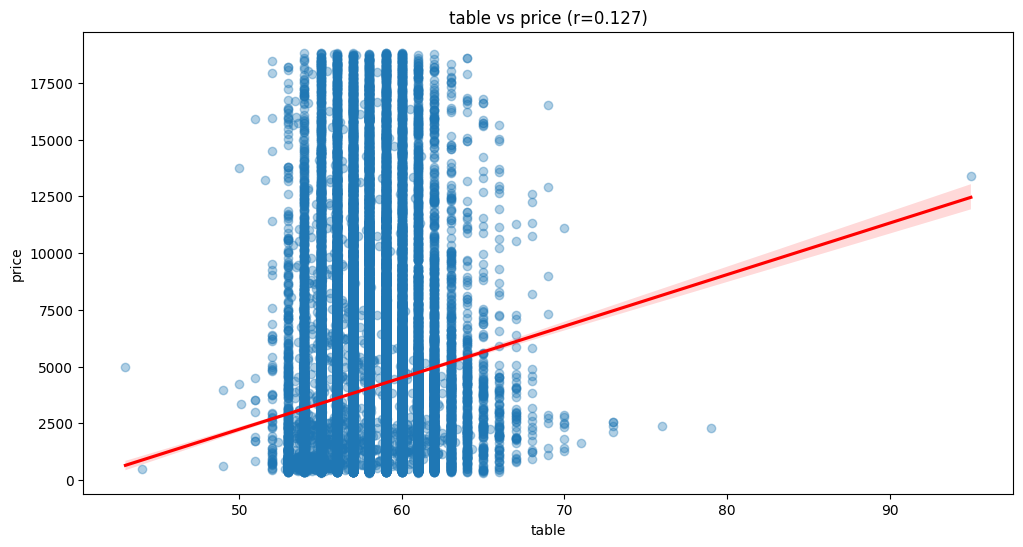

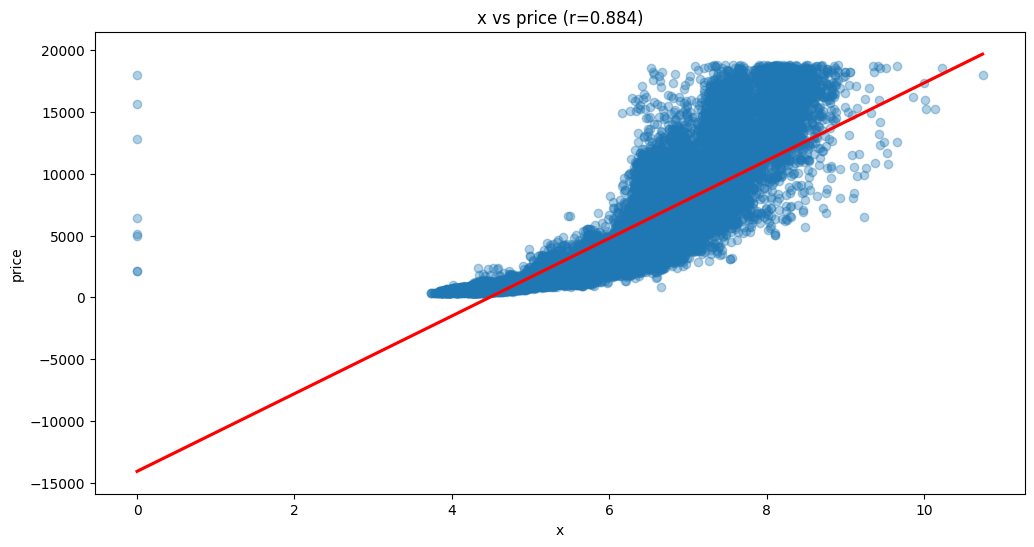

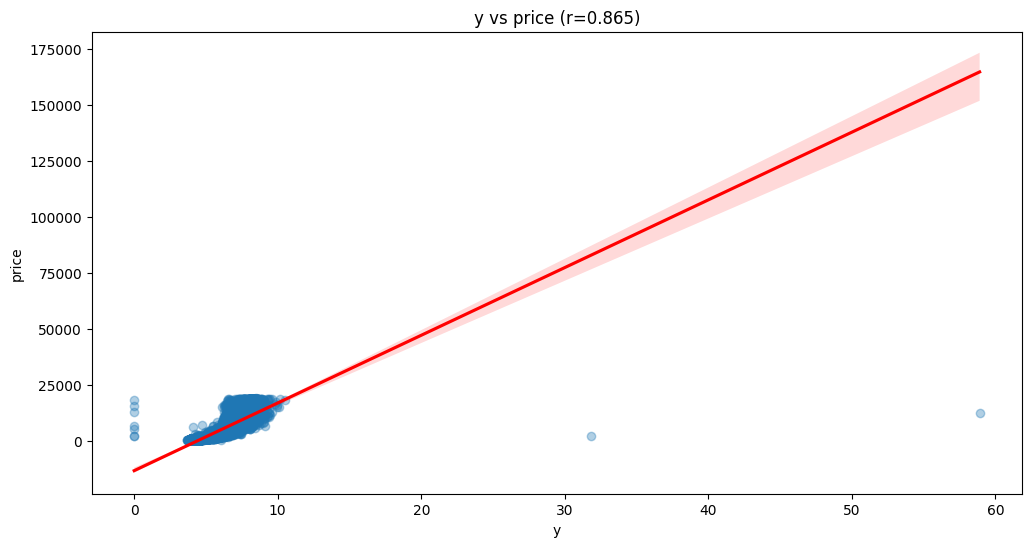

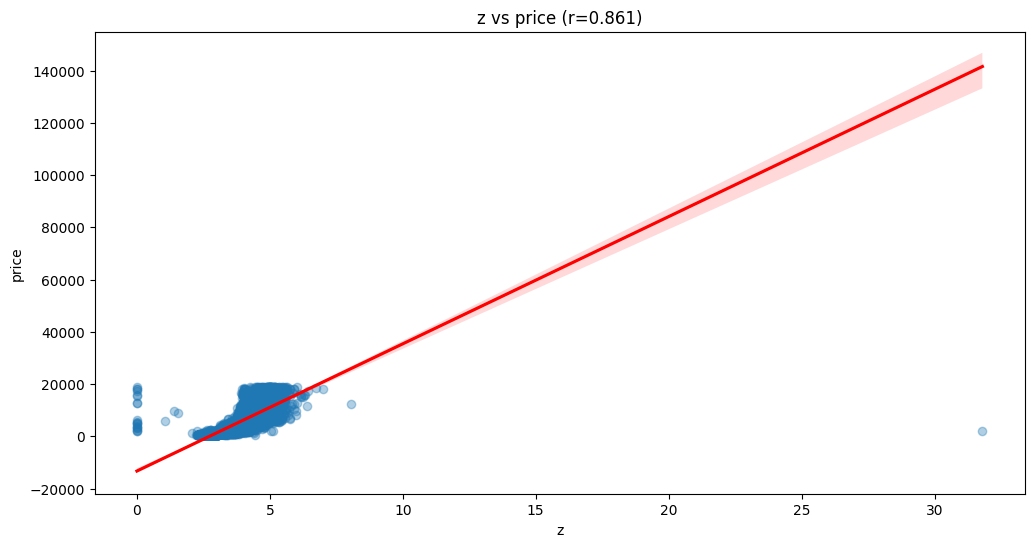

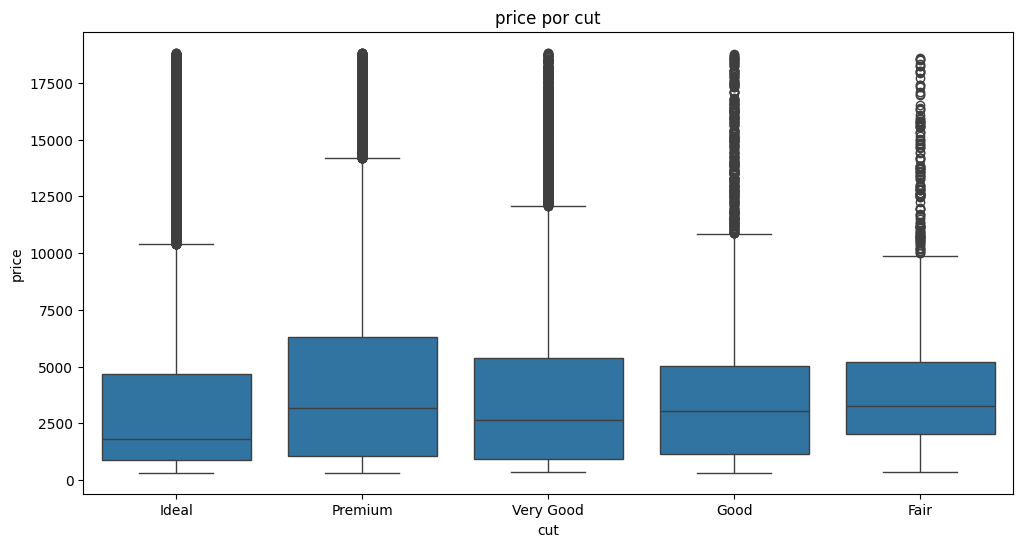

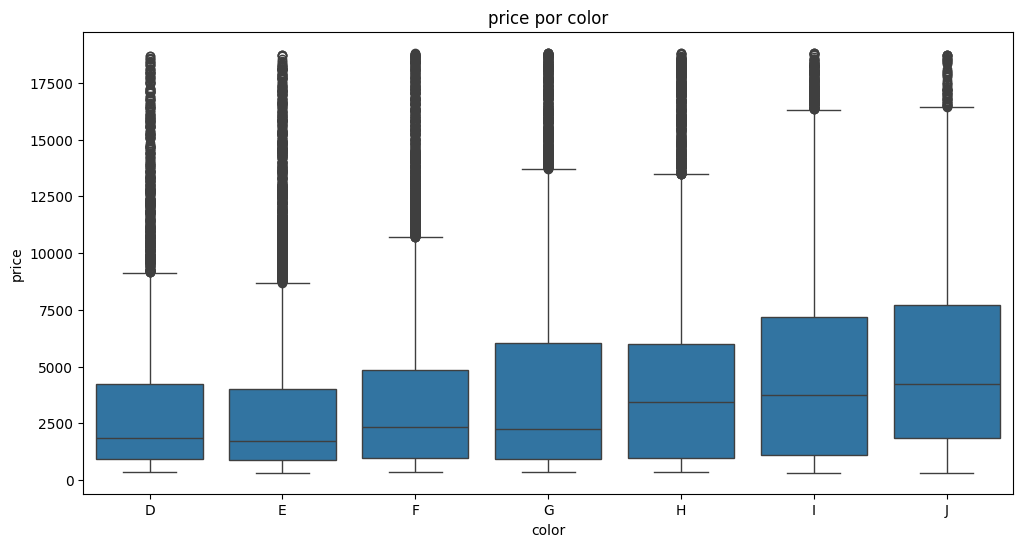

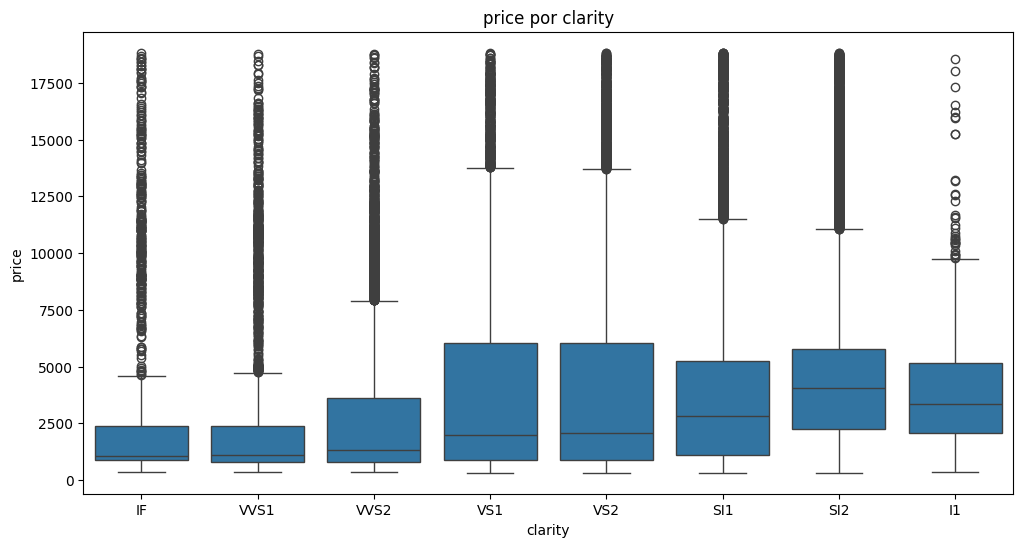

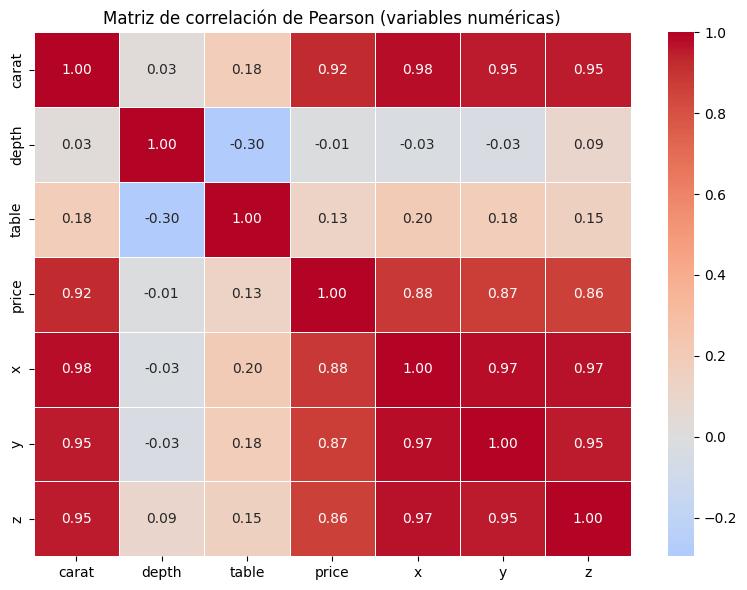

🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'carat' y 'price' con |r|=0.92 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'carat' y 'x' con |r|=0.98 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'carat' y 'y' con |r|=0.95 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'carat' y 'z' con |r|=0.95 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'price' y 'x' con |r|=0.88 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'price' y 'y' con |r|=0.87 ≥ 0.8: evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.
🔎 OBSERVACIÓN [P10 · multicolinealidad]: 'price' y 'z' con |r|=0.86 ≥ 0.8: evaluar eliminar una de las dos o

,variable,VIF
0,carat,21.60
1,depth,1.50
2,table,1.14
3,x,56.19
4,y,20.45
5,z,23.53


🔎 OBSERVACIÓN [P10 · vif]: 'carat': VIF=21.60 > 10.0 → multicolinealidad severa: evaluar eliminar la variable o combinarla con otra.
🔎 OBSERVACIÓN [P10 · vif]: 'x': VIF=56.19 > 10.0 → multicolinealidad severa: evaluar eliminar la variable o combinarla con otra.
🔎 OBSERVACIÓN [P10 · vif]: 'y': VIF=20.45 > 10.0 → multicolinealidad severa: evaluar eliminar la variable o combinarla con otra.
🔎 OBSERVACIÓN [P10 · vif]: 'z': VIF=23.53 > 10.0 → multicolinealidad severa: evaluar eliminar la variable o combinarla con otra.
         DIAGNÓSTICO COMPLETADO · 27 observaciones registradas          
Para la interpretación final ejecuta: eda.obtener_hallazgos()


,punto,tipo,detalle
0,4,duplicados,146 filas duplicadas detectadas: evaluar si se...
1,6,outliers,'carat': 1889 valores atípicos (3.50%) y 40 ex...
2,6,outliers,'depth': 2545 valores atípicos (4.72%) y 278 e...
3,6,outliers,'table': 605 valores atípicos (1.12%) y 28 ext...
4,6,outliers,'price': 3540 valores atípicos (6.56%) y 120 e...
5,6,outliers,'x': 32 valores atípicos (0.06%) y 0 extremos....
6,6,outliers,'y': 29 valores atípicos (0.05%) y 2 extremos....
7,6,outliers,'z': 49 valores atípicos (0.09%) y 2 extremos....
8,8,sesgo_target,El target 'price' tiene |skew|=1.62 > 1.0: la ...
9,9,sesgo,'carat': |skew|=1.12 > 1.0 → distribución asim...


In [42]:
# Instanciamos la herramienta declarando el target continuo del problema de regresión
eda = AutoEDA(df, target_col='price', figsize=(12, 6))   # target_col='price' habilita los análisis del target

# Ejecutamos los 10 puntos de EDA de clase con UNA sola llamada (automatización 100 %)
eda.run_analysis()

# Recuperamos la bitácora de observaciones: insumo directo de la sección de interpretación
hallazgos = eda.obtener_hallazgos()                      # DataFrame con columnas: punto, tipo, detalle
display(hallazgos)                                       # tabla interactiva de hallazgos 🔎 (en script: print(hallazgos))




### ¿Cómo interpretar la salida?

- **Faltantes y duplicados**: Diamonds no tiene valores nulos ni duplicados; tu herramienta lo confirmará con ✓.
- **Outliers**: `price`, `carat` y las dimensiones presentan valores atípicos altos (diamantes caros/grandes). NO los elimines: son datos reales y los árboles los manejan bien. Si los eliminaras, dilo explícitamente y justifícalo.
- **Sesgo**: `price` está sesgada a la derecha (muchos diamantes baratos, pocos carísimos). Opción avanzada (no obligatoria): modelar `log(price)`. Con árboles no es necesario.
- **Multicolinealidad (VIF)**: tu `AutoEDA` **va a marcar** 🔎 a `carat`, `x`, `y` y `z` (correlaciones > 0.95 entre sí: el peso y las dimensiones miden casi lo mismo). Decisión documentada: **conservamos todas** porque los modelos de árboles son robustos a la multicolinealidad y porque para XAI es más interesante ver cómo se reparten la importancia. Si tu modelo final fuera una regresión lineal, aquí sí convendría eliminar `x`, `y`, `z`.
- **Relación con el objetivo**: `carat` es la feature más correlacionada con `price` (~0.92): anticipa que dominará las importancias en los Pasos 10-12.

---

## Paso 3 — Preprocesamiento y partición de datos

### ¿Qué es y para qué sirve?

- **Preprocesamiento**: dejar los datos en un formato que los algoritmos puedan usar: rellenar faltantes, escalar, codificar categóricas.
- **Partición**: separar los datos en **entrenamiento** (para aprender) y **prueba** (para evaluar como si fueran datos nuevos). La regla de oro: el conjunto de prueba **no se toca** hasta la evaluación final.


**Celda 6 — Separar features y objetivo, y partir los datos**


In [43]:
# Herramientas de sklearn para partición, validación cruzada y pipelines
from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separamos features (X) de la variable objetivo (y)
X = df.drop(columns=['price'])         # X = todas las columnas MENOS la objetivo
y = df['price']                        # y = solo la columna objetivo (precio en USD)

# Partición 80% entrenamiento / 20% prueba
# test_size=0.2 -> 20% para test; random_state=42 -> partición reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Límite común de datos y evaluaciones para que las comparaciones de búsqueda sean reproducibles y asequibles.
MAX_MUESTRAS_BUSQUEDA = 8000  # usa como máximo 8.000 ejemplos para ajustar hiperparámetros
N_SPLITS = 3                  # tres folds mantienen una comparación común con un coste moderado
N_ITER = 20                   # iteraciones de RandomizedSearch y BayesSearchCV
N_TRIALS = 20                 # trials de Optuna

# Usamos la misma submuestra de entrenamiento en todas las búsquedas; el test queda completamente aparte.
X_tune = X_train.sample(n=min(MAX_MUESTRAS_BUSQUEDA, len(X_train)), random_state=42)
y_tune = y_train.loc[X_tune.index]

# Validación cruzada compartida para comparar métodos con los mismos folds.
cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)




**Celda 7 — Pipelines de preprocesamiento**


In [44]:
# Pipeline para columnas NUMÉRICAS: rellenar faltantes y estandarizar
pipeline_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # rellena NaN con la MEDIANA de cada columna (robusta a outliers)
    ('scaler', StandardScaler())                     # estandariza: resta la media y divide por la desviación (media=0, std=1)
])

# Pipeline para columnas CATEGÓRICAS: rellenar faltantes y codificar
pipeline_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),   # rellena NaN con la MODA (el valor más frecuente)
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))     # convierte categorías en columnas 0/1 (sin orden artificial)
])

# ColumnTransformer: aplica cada pipeline al tipo de columna que le corresponde
preprocesador = ColumnTransformer(transformers=[
    ('num', pipeline_numerico, make_column_selector(dtype_include=np.number)),   # numéricas -> pipeline_numérico
    ('cat', pipeline_categorico, make_column_selector(dtype_exclude=np.number)), # categóricas (cut, color, clarity) -> one-hot
])




### ¿Cómo interpretar esta parte?

- `SimpleImputer(median)`: la mediana es robusta a outliers; la media se distorsiona con valores extremos.
- `StandardScaler`: imprescindible para modelos sensibles a la escala (regresión lineal, SVM, redes). Para árboles no es necesario, pero **no les hace daño** y nos permite mantener un pipeline único.
- `OneHotEncoder`: convierte `cut` (5 categorías), `color` (7) y `clarity` (8) en 20 columnas binarias. Evita el error de asignarles un "orden" artificial (problema de la codificación ordinal/LabelEncoder).
- `make_column_selector`: selecciona columnas automáticamente por su tipo, así el mismo código funciona con cualquier dataset.

---

## Paso 4 — Modelos base (línea base)


### ¿Qué es y para qué sirve?

Antes de optimizar hiperparámetros, entrenamos los 2 modelos **con sus valores por defecto** para tener una referencia ("línea base"): si después de horas de búsqueda no mejoras la línea base, algo anda mal. También comparamos contra un modelo "tonto" que predice siempre la media: si tu modelo no supera eso, no aprendió nada.

**Modelos elegidos (los mismos del curso):**

- **Random Forest** muchos árboles de decisión
- **XGBoost** boosting extremo por gradiente; árboles en secuencia que corrigen los errores de los anteriores, con regularización incorporada. Suele lograr el mejor score, pero es más sensible a hiperparámetros.

Ambos ofrecen `feature_importances_` nativo, lo que facilita la sección de XAI.

**Celda 8 — Línea base con hiperparámetros por defecto**


In [45]:
# Modelos y métricas
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

# Referencia "tonta": siempre predice la media del objetivo
dummy = DummyRegressor(strategy='mean')
scores_dummy = cross_val_score(dummy, X_tune, y_tune, cv=cv, scoring='neg_mean_squared_error')  # MSE negativo en CV
print(f"Dummy (predice la media): RMSE CV = {np.sqrt(-scores_dummy.mean()):.0f} USD")

# Nuestros 2 modelos base, con hiperparámetros por defecto
# enable_categorical=False: como ya codificamos las categóricas con OneHot, XGBoost recibe solo números
# (si tu versión de xgboost es < 2.0, quita ese argumento)
modelos_base = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42, enable_categorical=False),
}

# Evaluamos cada modelo base envuelto en el pipeline de preprocesamiento
for nombre, modelo in modelos_base.items():                        # iteramos sobre los 2 modelos
    pipe = Pipeline(steps=[
        ('preprocesador', preprocesador),                          # mismo preprocesamiento para ambos
        ('modelo', modelo)                                         # el modelo base del turno
    ])
    # Validación cruzada con MSE negativo; sqrt(-score) lo convierte en RMSE
    scores = cross_val_score(pipe, X_tune, y_tune, cv=cv, scoring='neg_mean_squared_error')
    print(f"{nombre}: RMSE CV = {np.sqrt(-scores.mean()):.0f} USD")


Dummy (predice la media): RMSE CV = 3987 USD
Random Forest: RMSE CV = 699 USD
XGBoost: RMSE CV = 684 USD




### ¿Cómo interpretar la salida?

- El RMSE del Dummy (~3.990 USD ≈ desviación estándar de `price`) es la "barrera mínima": si el modelo no baja de ahí, no aprende nada.
- Ambos modelos base deberían bajar claramente del Dummy (típicamente RMSE ≈ 540-570 USD en Diamonds).
- Anota estos números: los usarás en las conclusiones para mostrar cuánto mejoró la búsqueda de hiperparámetros.

### Glosario de hiperparámetros que optimizaremos

- **n_estimators**: número de árboles. Más árboles = más precisión, pero más tiempo.
- **max_depth**: profundidad máxima de cada árbol. Muy profundo = memoriza (overfitting); muy bajo = no aprende (underfitting).
- **min_samples_split** / **min_samples_leaf**: mínimo de muestras para dividir un nodo / quedar en una hoja. Valores altos regularizan.
- **max_features**: cuántas features considera cada árbol en cada división (`sqrt`, `log2` o todas). Añade diversidad entre árboles.
- **learning_rate** (boosting): cuánto aporta cada árbol nuevo. Bajo = aprende lento pero generaliza mejor (requiere más árboles).
- **subsample** (boosting): fracción de filas usada por cada árbol. Menor a 1 reduce overfitting.
- **min_child_weight** (XGBoost): suma mínima de pesos de instancias en una hoja; valores altos regularizan (equivale a `min_samples_leaf`).
- **colsample_bytree** (XGBoost): fracción de columnas que usa cada árbol (equivalente a `max_features`).

---

## Paso 5 — Grid Search

### ¿Qué es y para qué sirve?

Grid Search **prueba todas las combinaciones** de los valores que le des. Es la forma más sistemática, pero sufre la **explosión combinatoria**: 3 valores × 3 valores × 4 valores = 36 combinaciones × 5 folds = 180 entrenamientos. Por eso los grids de demostración deben ser pequeños.

> Importante: como el modelo vive dentro de un Pipeline, los nombres de los parámetros llevan el prefijo `modelo__` (así sklearn sabe que `n_estimators` es del paso llamado `modelo`).

**Celda 9 — Grid Search para Random Forest**


In [46]:
# Importamos el buscador por rejilla
from sklearn.model_selection import GridSearchCV

# Inicializamos la lista que acumulará los resultados de TODAS las búsquedas
# (la usaremos en el Paso 8 para comparar métodos y tiempos)
resumen = []
mejores_estimadores = {}

# Pipeline del modelo (el preprocesador es el mismo objeto de siempre: sklearn lo clona)
pipe_rf = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', RandomForestRegressor(random_state=42))
])

# Espacio de búsqueda: 2 x 2 x 1 = 4 combinaciones (chico para que corra rápido)
param_grid_rf = {
    'modelo__n_estimators': [50, 100],        # cuántos árboles probar
    'modelo__max_depth': [10, 20],       # None = sin límite de profundidad
    'modelo__min_samples_split': [2],      # mínimo de muestras para dividir un nodo
}

# Configuramos el GridSearch: evalúa cada combinación con validación cruzada de 3 folds
grid_rf = GridSearchCV(
    estimator=pipe_rf,                          # pipeline que contiene el modelo
    param_grid=param_grid_rf,                   # las 4 combinaciones a probar
    scoring='neg_mean_squared_error',           # métrica interna (MSE negativo; menor es mejor)
    cv=cv,                                      # mismos folds que usaremos en todos los métodos
    n_jobs=-1                                   # usa todos los núcleos del CPU (paraleliza)
)

# Medimos el tiempo de ejecución de la búsqueda
inicio = time.perf_counter()                    # marca de tiempo inicial
grid_rf.fit(X_tune, y_tune)                   # ejecuta las 4 x 3 = 12 combinaciones de entrenamiento
mejores_estimadores[("Grid Search", "Random Forest")] = grid_rf.best_estimator_
tiempo_grid_rf = time.perf_counter() - inicio   # tiempo total transcurrido

# Evaluamos el mejor modelo encontrado sobre el conjunto de PRUEBA (que nunca vio)
y_pred_test = grid_rf.predict(X_test)                          # predicciones del mejor estimador
rmse_test_grid_rf = np.sqrt(mean_squared_error(y_test, y_pred_test))  # RMSE real en test

# Reportamos resultados del experimento
print('Mejores hiperparámetros:', grid_rf.best_params_)         # combinación ganadora
print(f"RMSE CV: {np.sqrt(-grid_rf.best_score_):.0f} | RMSE Test: {rmse_test_grid_rf:.0f} | Tiempo: {tiempo_grid_rf:.2f} s")

# Registramos el experimento en la tabla comparativa (Paso 8)
resumen.append({
    'Metodo': 'Grid Search', 'Modelo': 'Random Forest',
    'RMSE CV': np.sqrt(-grid_rf.best_score_),                   # score de validación cruzada
    'RMSE Test': rmse_test_grid_rf,                             # score real sobre test
    'Tiempo (s)': tiempo_grid_rf                                # tiempo de ejecución
})


Mejores hiperparámetros: {'modelo__max_depth': 20, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 100}
RMSE CV: 699 | RMSE Test: 633 | Tiempo: 35.49 s




**Celda 10 — Grid Search para XGBoost**


In [47]:
# Pipeline del segundo modelo (XGBoost, el modelo de las prácticas 2.2 y 6A)
pipe_xgb = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', XGBRegressor(random_state=42, enable_categorical=False))
])

# Espacio de búsqueda: 2 x 2 x 2 = 8 combinaciones
param_grid_xgb = {
    'modelo__n_estimators': [100, 300],       # cuántos árboles en la secuencia
    'modelo__learning_rate': [0.05, 0.1],     # cuánto aporta cada árbol (paso de aprendizaje)
    'modelo__max_depth': [3, 5],              # profundidad de cada árbol
}

# Configuramos la búsqueda por rejilla (misma métrica, mismos folds)
grid_xgb = GridSearchCV(estimator=pipe_xgb, param_grid=param_grid_xgb,
                        scoring='neg_mean_squared_error', cv=cv, n_jobs=-1)

# Medimos tiempo y ejecutamos
inicio = time.perf_counter()
grid_xgb.fit(X_tune, y_tune)
mejores_estimadores[("Grid Search", "XGBoost")] = grid_xgb.best_estimator_
tiempo_grid_xgb = time.perf_counter() - inicio

# Evaluación en test del mejor modelo encontrado
y_pred_test = grid_xgb.predict(X_test)
rmse_test_grid_xgb = np.sqrt(mean_squared_error(y_test, y_pred_test))

print('Mejores hiperparámetros:', grid_xgb.best_params_)
print(f"RMSE CV: {np.sqrt(-grid_xgb.best_score_):.0f} | RMSE Test: {rmse_test_grid_xgb:.0f} | Tiempo: {tiempo_grid_xgb:.2f} s")

# Registramos el experimento
resumen.append({
    'Metodo': 'Grid Search', 'Modelo': 'XGBoost',
    'RMSE CV': np.sqrt(-grid_xgb.best_score_),
    'RMSE Test': rmse_test_grid_xgb,
    'Tiempo (s)': tiempo_grid_xgb
})


Mejores hiperparámetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 5, 'modelo__n_estimators': 300}
RMSE CV: 657 | RMSE Test: 624 | Tiempo: 7.10 s




### ¿Cómo interpretar la salida?

- `best_params_` te dice la combinación ganadora. Si el mejor valor quedó en el **borde** del rango (por ejemplo `n_estimators=300` siendo el máximo probado), sospecha que el óptimo podría estar fuera del rango: amplía el grid.
- `best_score_` es el RMSE de validación cruzada (promedio de los 3 folds del mejor modelo).
- El RMSE en test es la evaluación honesta: el modelo nunca vio esos datos.
- **Limitación de Grid**: solo explora los puntos exactos que le diste. Si el óptimo está "entre" dos valores, Grid no lo encuentra. Por eso existen los siguientes métodos.

---

## Paso 6 — Búsqueda Aleatoria (Randomized Search)

### ¿Qué es y para qué sirve?

En vez de probar todas las combinaciones, **muestrea N combinaciones al azar** del espacio. Ventajas:

- Puedes definir **distribuciones** (rangos continuos), no solo listas de valores.
- Con el mismo presupuesto de tiempo explora zonas más variadas que Grid.
- Bergstra & Bengio (2012) demostraron que suele alcanzar resultados casi óptimos con muchos menos intentos, porque normalmente solo unos pocos hiperparámetros realmente importan.
- (RandomizedSearchCV + RandomForestRegressor + `neg_mean_squared_error`).

**Celda 11 — Búsqueda aleatoria para Random Forest**


In [48]:
# Importamos el buscador aleatorio
from sklearn.model_selection import RandomizedSearchCV

# Espacio de búsqueda con DISTRIBUCIONES (rangos), no listas fijas
param_dist_rf = {
    'modelo__n_estimators': randint(100, 501),        # entero uniforme entre 100 y 500
    'modelo__max_depth': randint(5, 31),              # entero uniforme entre 5 y 30
    'modelo__min_samples_split': randint(2, 21),      # entero uniforme entre 2 y 20
    'modelo__min_samples_leaf': randint(1, 11),       # entero uniforme entre 1 y 10
    'modelo__max_features': ['sqrt', 'log2', 1.0],    # lista: se elige un valor al azar (1.0 = todas)
}

# Buscador aleatorio: 20 combinaciones al azar, 3 folds cada una
random_rf = RandomizedSearchCV(
    estimator=pipe_rf,                        # reutilizamos el mismo pipeline del Grid
    param_distributions=param_dist_rf,        # espacio definido con distribuciones
    n_iter=N_ITER,                                # número de combinaciones a muestrear
    scoring='neg_mean_squared_error',         # misma métrica que Grid (comparación justa)
    cv=cv,                                    # mismos folds
    n_jobs=-1,                                # paralelizar
    random_state=42                           # muestreo reproducible
)

# Medimos tiempo y ejecutamos
inicio = time.perf_counter()
random_rf.fit(X_tune, y_tune)
mejores_estimadores[("Aleatoria", "Random Forest")] = random_rf.best_estimator_
tiempo_random_rf = time.perf_counter() - inicio

# Evaluación en test
y_pred_test = random_rf.predict(X_test)
rmse_test_random_rf = np.sqrt(mean_squared_error(y_test, y_pred_test))

print('Mejores hiperparámetros:', random_rf.best_params_)
print(f"RMSE CV: {np.sqrt(-random_rf.best_score_):.0f} | RMSE Test: {rmse_test_random_rf:.0f} | Tiempo: {tiempo_random_rf:.2f} s")

# Registramos el experimento
resumen.append({
    'Metodo': 'Aleatoria', 'Modelo': 'Random Forest',
    'RMSE CV': np.sqrt(-random_rf.best_score_),
    'RMSE Test': rmse_test_random_rf,
    'Tiempo (s)': tiempo_random_rf
})


Mejores hiperparámetros: {'modelo__max_depth': 28, 'modelo__max_features': 1.0, 'modelo__min_samples_leaf': 6, 'modelo__min_samples_split': 3, 'modelo__n_estimators': 443}
RMSE CV: 801 | RMSE Test: 695 | Tiempo: 89.83 s




**Celda 12 — Búsqueda aleatoria para XGBoost**


In [49]:
# Espacio con distribuciones para XGBoost
param_dist_xgb = {
    'modelo__n_estimators': randint(100, 401),            # entero uniforme entre 100 y 400
    'modelo__learning_rate': uniform(0.01, 0.2),          # uniforme CONTINUA entre 0.01 y 0.21
    'modelo__max_depth': randint(3, 8),                   # entero uniforme entre 3 y 7
    'modelo__subsample': uniform(0.6, 0.4),               # uniforme continua entre 0.6 y 1.0
    'modelo__min_child_weight': randint(1, 11),           # entero uniforme entre 1 y 10 (regularización)
}

# Buscador aleatorio: 20 combinaciones al azar
random_xgb = RandomizedSearchCV(
    estimator=pipe_xgb,
    param_distributions=param_dist_xgb,
    n_iter=N_ITER,
    scoring='neg_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    random_state=42
)

# Medimos tiempo y ejecutamos
inicio = time.perf_counter()
random_xgb.fit(X_tune, y_tune)
mejores_estimadores[("Aleatoria", "XGBoost")] = random_xgb.best_estimator_
tiempo_random_xgb = time.perf_counter() - inicio

# Evaluación en test
y_pred_test = random_xgb.predict(X_test)
rmse_test_random_xgb = np.sqrt(mean_squared_error(y_test, y_pred_test))

print('Mejores hiperparámetros:', random_xgb.best_params_)
print(f"RMSE CV: {np.sqrt(-random_xgb.best_score_):.0f} | RMSE Test: {rmse_test_random_xgb:.0f} | Tiempo: {tiempo_random_xgb:.2f} s")

# Registramos el experimento
resumen.append({
    'Metodo': 'Aleatoria', 'Modelo': 'XGBoost',
    'RMSE CV': np.sqrt(-random_xgb.best_score_),
    'RMSE Test': rmse_test_random_xgb,
    'Tiempo (s)': tiempo_random_xgb
})


Mejores hiperparámetros: {'modelo__learning_rate': np.float64(0.0849080237694725), 'modelo__max_depth': 7, 'modelo__min_child_weight': 8, 'modelo__n_estimators': 288, 'modelo__subsample': np.float64(0.8387400631785948)}
RMSE CV: 657 | RMSE Test: 617 | Tiempo: 7.91 s




### ¿Cómo interpretar la salida?

- `uniform(loc, scale)` de scipy muestrea en el intervalo `[loc, loc + scale)`. Por eso `uniform(0.01, 0.2)` va de 0.01 a 0.21.
- Compara el RMSE obtenido con el de Grid: con una cantidad similar de entrenamientos (o menos), la búsqueda aleatoria suele empatar o superar a Grid, porque explora el espacio de forma más eficiente.
- El resultado es aleatorio (controlado por `random_state`): con más `n_iter` tiende a mejores resultados, pero con rendimientos decrecientes.

---

## Paso 7 — Optimización Bayesiana (Optuna y BayesSearchCV)

### ¿Qué es y para qué sirve?

A diferencia de Grid y Random (que prueban "a ciegas"), la optimización bayesiana **aprende de cada intento**:

1. Evalúa una combinación.
2. Un **modelo sustituto** (en Optuna, `TPESampler`; en scikit-optimize, procesos gaussianos) estima qué zonas del espacio son prometedoras según los resultados anteriores.
3. Una **función de adquisición** decide el siguiente punto a probar (equilibrando explotar buenas zonas y explorar zonas desconocidas).
4. Repite.

Resultado: converge más rápido a buenos hiperparámetros, especialmente con espacios grandes, y prueba valores **continuos** con total libertad (p. ej. `learning_rate=0.073`, imposible en un Grid discreto).

> En clase viste las **dos implementaciones**: Práctica 6A con **Optuna** (`TPESampler`) y Práctica 6B con **`BayesSearchCV`** (scikit-optimize). Abajo están ambas, aplicadas a regresión.
>
> **Diferencia metodológica con la Práctica 6A**: allí la función objetivo evaluaba con `.score(X_test, y_test)`; aquí evaluamos con **validación cruzada sobre el entrenamiento** para que el conjunto de test NO participe en la selección de hiperparámetros (evita fuga de datos). Es la misma idea, con una práctica más rigurosa.

### 9.1 Optuna (TPESampler) — como la Práctica 6A

**Celda 13 — Función objetivo para Random Forest (Optuna)**


In [50]:
# Importamos Optuna (librería líder de optimización bayesiana de hiperparámetros)
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)   # silenciamos los mensajes de progreso de cada trial

# Función objetivo: Optuna la llamará una vez por "trial" (intento)
# Cada trial SUGIERE una combinación de hiperparámetros; nosotros devolvemos el score a minimizar
def objetivo_rf(trial):
    # El trial sugiere valores dentro de los rangos definidos
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),            # entero en [100, 500]
        'max_depth': trial.suggest_int('max_depth', 5, 30),                      # entero en [5, 30]
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),      # entero en [2, 20]
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),        # entero en [1, 10]
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 1.0]),  # entre opciones
    }
    modelo = RandomForestRegressor(**params, random_state=42, n_jobs=-1)  # modelo con la combinación sugerida
    pipe = Pipeline(steps=[('preprocesador', preprocesador), ('modelo', modelo)])  # pipeline completo
    scores = cross_val_score(pipe, X_tune, y_tune, cv=cv, scoring='neg_mean_squared_error')  # CV con los MISMOS folds
    return float(np.sqrt(-scores.mean()))   # devolvemos el RMSE: Optuna lo MINIMIZARÁ

# Creamos el estudio: direction='minimize' porque RMSE menor es mejor
# TPESampler es el modelo sustituto (Tree-structured Parzen Estimator), el mismo de la Práctica 6A
estudio_rf = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

# Ejecutamos N_TRIALS trials (intentos inteligentes)
inicio = time.perf_counter()
estudio_rf.optimize(objetivo_rf, n_trials=N_TRIALS)
tiempo_bayes_rf = time.perf_counter() - inicio

print('Mejores hiperparámetros:', estudio_rf.best_params)     # mejor combinación encontrada
print(f"RMSE CV: {estudio_rf.best_value:.0f} | Tiempo: {tiempo_bayes_rf:.2f} s")

# Optuna no devuelve el modelo ya entrenado: lo reconstruimos y entrenamos a mano
# (igual que la Práctica 6A: best_model = Model(**best_params))
mejor_rf_bayes = RandomForestRegressor(**estudio_rf.best_params, random_state=42, n_jobs=-1)
pipe_mejor_rf_bayes = Pipeline(steps=[('preprocesador', preprocesador), ('modelo', mejor_rf_bayes)])
pipe_mejor_rf_bayes.fit(X_tune, y_tune)                     # entrenamos con la combinación ganadora
mejores_estimadores[("Bayesiana", "Random Forest")] = pipe_mejor_rf_bayes

# Evaluación en test
y_pred_test = pipe_mejor_rf_bayes.predict(X_test)
rmse_test_bayes_rf = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"RMSE Test: {rmse_test_bayes_rf:.0f}")

# Registramos el experimento
resumen.append({
    'Metodo': 'Bayesiana', 'Modelo': 'Random Forest',
    'RMSE CV': estudio_rf.best_value,
    'RMSE Test': rmse_test_bayes_rf,
    'Tiempo (s)': tiempo_bayes_rf
})


Mejores hiperparámetros: {'n_estimators': 447, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
RMSE CV: 822 | Tiempo: 23.63 s
RMSE Test: 764




**Celda 14 — Función objetivo para XGBoost (Optuna)**


In [51]:
# Función objetivo para XGBoost (misma lógica que la anterior)
def objetivo_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),                 # entero en [100, 400]
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),  # CONTINUO log-uniforme en [0.01, 0.2]
        'max_depth': trial.suggest_int('max_depth', 3, 8),                           # entero en [3, 8]
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),                     # continuo en [0.6, 1.0]
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),            # entero en [1, 10] (regularización)
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),       # fracción de columnas por árbol
    }
    modelo = XGBRegressor(**params, random_state=42, enable_categorical=False)       # modelo con la combinación sugerida
    pipe = Pipeline(steps=[('preprocesador', preprocesador), ('modelo', modelo)])
    scores = cross_val_score(pipe, X_tune, y_tune, cv=cv, scoring='neg_mean_squared_error')
    return float(np.sqrt(-scores.mean()))                                            # RMSE a minimizar

# Estudio para XGBoost
estudio_xgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

# Ejecutamos N_TRIALS trials
inicio = time.perf_counter()
estudio_xgb.optimize(objetivo_xgb, n_trials=N_TRIALS)
tiempo_bayes_xgb = time.perf_counter() - inicio

print('Mejores hiperparámetros:', estudio_xgb.best_params)
print(f"RMSE CV: {estudio_xgb.best_value:.0f} | Tiempo: {tiempo_bayes_xgb:.2f} s")

# Reconstruimos y entrenamos el mejor modelo encontrado
mejor_xgb_bayes = XGBRegressor(**estudio_xgb.best_params, random_state=42, enable_categorical=False)
pipe_mejor_xgb_bayes = Pipeline(steps=[('preprocesador', preprocesador), ('modelo', mejor_xgb_bayes)])
pipe_mejor_xgb_bayes.fit(X_tune, y_tune)
mejores_estimadores[("Bayesiana", "XGBoost")] = pipe_mejor_xgb_bayes

# Evaluación en test
y_pred_test = pipe_mejor_xgb_bayes.predict(X_test)
rmse_test_bayes_xgb = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"RMSE Test: {rmse_test_bayes_xgb:.0f}")

# Registramos el experimento
resumen.append({
    'Metodo': 'Bayesiana', 'Modelo': 'XGBoost',
    'RMSE CV': estudio_xgb.best_value,
    'RMSE Test': rmse_test_bayes_xgb,
    'Tiempo (s)': tiempo_bayes_xgb
})


Mejores hiperparámetros: {'n_estimators': 117, 'learning_rate': 0.13394334706750485, 'max_depth': 6, 'subsample': 0.8832290311184181, 'min_child_weight': 1, 'colsample_bytree': 0.9879639408647978}
RMSE CV: 658 | Tiempo: 4.98 s
RMSE Test: 615




**Celda 15 — Visualizaciones de Optuna (como la Práctica 6A)**


In [52]:
# Evolución del mejor RMSE trial a trial (muestra que la búsqueda APRENDE y mejora)
# (requiere plotly: %pip install plotly)
optuna.visualization.plot_optimization_history(estudio_xgb)

# Importancia de cada hiperparámetro en el resultado:
# útil para saber en qué hiperparámetro vale la pena invertir más tiempo refinando
optuna.visualization.plot_param_importances(estudio_xgb)




### BayesSearchCV (scikit-optimize)


**Celda 16 — Búsqueda bayesiana con BayesSearchCV (opcional, Práctica 6B)**


In [53]:
# Implementación de optimización bayesiana de la Práctica 6B (scikit-optimize)
# %pip install scikit-optimize
from skopt import BayesSearchCV                 # buscador bayesiano con API estilo sklearn
from skopt.space import Real, Integer, Categorical   # tipos de espacio: continuo, entero y categórico

# Espacio de búsqueda con rangos guiados (no puramente al azar, como en Randomized)
espacio_xgb = {
    'modelo__n_estimators': Integer(100, 400),          # entero entre 100 y 400
    'modelo__learning_rate': Real(0.01, 0.2, prior='log-uniform'),  # continuo en escala logarítmica
    'modelo__max_depth': Integer(3, 8),                 # entero entre 3 y 8
    'modelo__subsample': Real(0.6, 1.0, prior='uniform'),         # continuo uniforme
    'modelo__min_child_weight': Integer(1, 10),         # entero entre 1 y 10
}

# Configuramos la búsqueda bayesiana (API idéntica a Grid/RandomizedSearchCV)
bayes_xgb = BayesSearchCV(
    estimator=pipe_xgb,                # pipeline del modelo
    search_spaces=espacio_xgb,         # espacio de búsqueda bayesiano
    n_iter=N_ITER,                    # número de evaluaciones guiadas
    scoring='neg_mean_squared_error',  # misma métrica de comparación
    cv=cv,                             # mismos folds
    n_jobs=-1,
    random_state=42
)

# Medimos tiempo y ejecutamos
inicio = time.perf_counter()
bayes_xgb.fit(X_tune, y_tune)
mejores_estimadores[("Bayesiana (skopt)", "XGBoost")] = bayes_xgb.best_estimator_
tiempo_bayes_skopt = time.perf_counter() - inicio

# Evaluación en test
y_pred_test = bayes_xgb.predict(X_test)
rmse_test_bayes_skopt = np.sqrt(mean_squared_error(y_test, y_pred_test))
print('Mejores hiperparámetros:', bayes_xgb.best_params_)
print(f"RMSE CV: {np.sqrt(-bayes_xgb.best_score_):.0f} | RMSE Test: {rmse_test_bayes_skopt:.0f} | Tiempo: {tiempo_bayes_skopt:.2f} s")

# Registramos el experimento (puedes comparar Optuna vs BayesSearchCV, las dos variantes bayesianas)
resumen.append({
    'Metodo': 'Bayesiana (skopt)', 'Modelo': 'XGBoost',
    'RMSE CV': np.sqrt(-bayes_xgb.best_score_),
    'RMSE Test': rmse_test_bayes_skopt,
    'Tiempo (s)': tiempo_bayes_skopt
})


Mejores hiperparámetros: OrderedDict({'modelo__learning_rate': 0.03790883530488498, 'modelo__max_depth': 8, 'modelo__min_child_weight': 2, 'modelo__n_estimators': 230, 'modelo__subsample': 0.6751820745469395})
RMSE CV: 650 | RMSE Test: 605 | Tiempo: 16.32 s




### ¿Cómo interpretar la salida?

- `trial.suggest_float(..., log=True)` muestrea en escala logarítmica: ideal para parámetros como `learning_rate` que funcionan en órdenes de magnitud (0.001, 0.01, 0.1...).
- Observa que Optuna prueba valores **continuos** (p. ej. `learning_rate=0.073`) imposibles de alcanzar con un Grid discreto.
- `plot_optimization_history` suele mostrar mejora rápida al inicio y estabilización después: evidencia de que el modelo sustituto está aprendiendo dónde buscar.
- `plot_param_importances` te dice qué hiperparámetros más influyen en el score (en Diamonds, típicamente `max_depth` y `learning_rate`).
- Si tu máquina es lenta, baja `n_trials`/`n_iter` a 15-20: la práctica sigue demostrando el concepto.

---

## Paso 8 — Comparación de métodos: score y tiempo


### ¿Qué es y para qué sirve?

Reunimos los experimentos en una tabla y dos gráficas. El ganador se selecciona por RMSE de validación cruzada (CV); el conjunto de prueba solo sirve para describir la evaluación final y no participa en la selección.

> Para hacer la ejecución asequible en Colab, los valores iniciales limitan el ajuste a 8.000 filas, 3 folds y 20 intentos por búsqueda. Puedes aumentar `MAX_MUESTRAS_BUSQUEDA`, `N_SPLITS`, `N_ITER` y `N_TRIALS` si dispones de más tiempo.

**Celda 17 — Tabla comparativa de resultados**


In [54]:
# Comparamos por RMSE CV para no escoger hiperparámetros usando el conjunto de prueba.
tabla = pd.DataFrame(resumen)                              # DataFrame a partir de los diccionarios acumulados
tabla = tabla.sort_values('RMSE CV').reset_index(drop=True)  # ordenamos por la métrica de validación cruzada

# El ganador se selecciona solo por CV; RMSE de test queda para evaluación descriptiva final.
ganador = min(resumen, key=lambda resultado: resultado['RMSE CV'])
print(f"Ganador por validación cruzada: {ganador['Metodo']} / {ganador['Modelo']}")

# Mostramos la tabla (display es función de notebook; también puedes escribir solo: tabla)
display(tabla.round(2))   # round(2) limita los decimales para que se lea mejor


Ganador por validación cruzada: Bayesiana (skopt) / XGBoost


,Metodo,Modelo,RMSE CV,RMSE Test,Tiempo (s)
0,Bayesiana (skopt),XGBoost,650.23,604.75,16.32
1,Grid Search,XGBoost,656.82,624.16,7.10
2,Aleatoria,XGBoost,657.29,617.18,7.91
3,Bayesiana,XGBoost,657.75,614.79,4.98
4,Grid Search,Random Forest,699.46,632.96,35.49
5,Aleatoria,Random Forest,800.55,694.92,89.83
6,Bayesiana,Random Forest,822.49,763.97,23.63




**Celda 18 — Gráfica 1: poder predictivo (RMSE en test)**


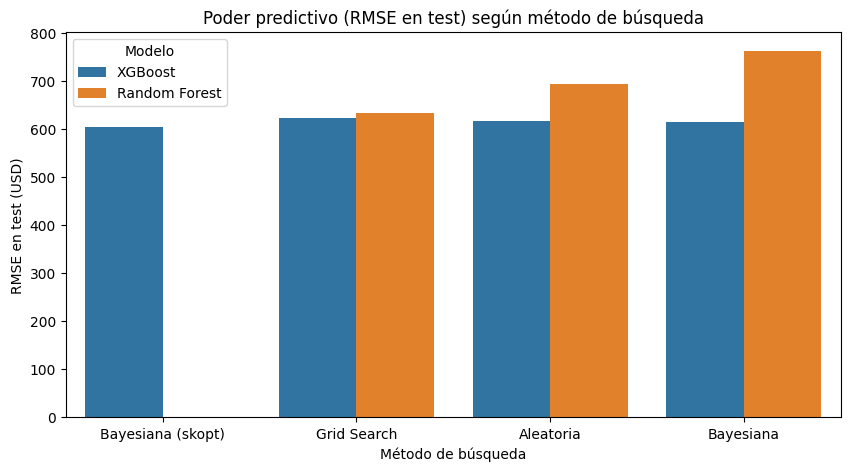

In [55]:
# Gráfica de barras: RMSE en test por método de búsqueda, separado por modelo
plt.figure(figsize=(10, 5))
sns.barplot(data=tabla, x='Metodo', y='RMSE Test', hue='Modelo')   # barras agrupadas por modelo
plt.title('Poder predictivo (RMSE en test) según método de búsqueda')  # MENOS es MEJOR
plt.ylabel('RMSE en test (USD)')
plt.xlabel('Método de búsqueda')
plt.legend(title='Modelo')
plt.show()




**Celda 19 — Gráfica 2: tiempos de ejecución**


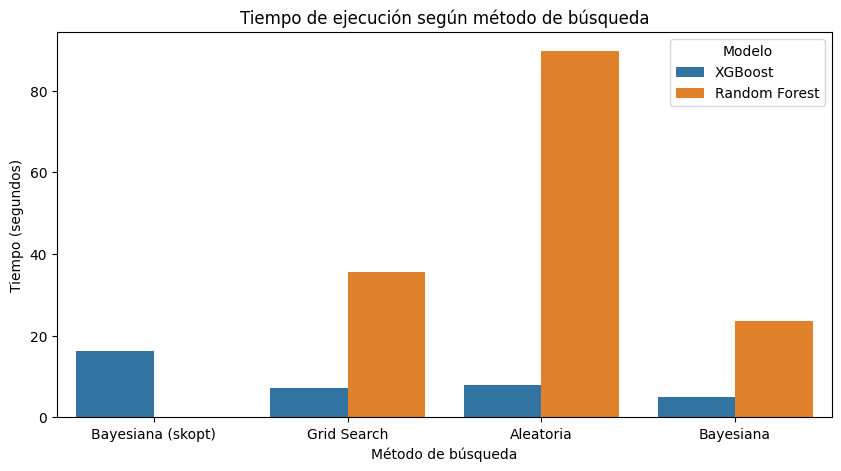

In [56]:
# Gráfica de barras: tiempo de ejecución por método de búsqueda
plt.figure(figsize=(10, 5))
sns.barplot(data=tabla, x='Metodo', y='Tiempo (s)', hue='Modelo')   # barras agrupadas por modelo
plt.title('Tiempo de ejecución según método de búsqueda')
plt.ylabel('Tiempo (segundos)')
plt.xlabel('Método de búsqueda')
plt.legend(title='Modelo')
plt.show()




### ¿Cómo interpretar y redactar esta parte?

Busca responder con **tus números** (no copies un texto genérico):

1. ¿Qué método logró el **menor RMSE en test**? Ese es el ganador en poder predictivo.
2. ¿Cuánto tiempo tardó cada método? Calcula proporciones (p. ej., "Grid tardó X segundos, la bayesiana Y segundos, es decir, Z veces menos").
3. ¿Cuál es la **mejor relación calidad/tiempo**? El patrón típico es: Grid encuentra buenos resultados pero es el más lento (y con grids reales, impracticable); Random consigue casi lo mismo con menos tiempo; la Bayesiana iguala o mejora el score explorando de forma inteligente. Si tus resultados difieren, explícalos tal cual (eso demuestra análisis honesto).
4. **Ojo con los tiempos**: dependen de tu hardware y de `n_jobs`; compáralos siempre en términos **relativos**, nunca absolutos.

---

## Paso 9 — Entrenamiento del modelo final


### ¿Qué es y para qué sirve?

Tomamos el **ganador** del paso anterior (mejor combinación de hiperparámetros) y entrenamos un **modelo nuevo y definitivo** con todos los datos de entrenamiento. Después, su única evaluación sobre el test nos da el veredicto final del proyecto.

### Decisión técnica: quitar el escalador

Nuestro ganador es un modelo de **árboles**, que es **invariante a transformaciones monótonas** de cada feature: si multiplicas/divides una columna por una constante, los árboles toman exactamente las mismas decisiones. Por eso, para el modelo final quitamos el `StandardScaler`:

- El rendimiento (RMSE/R²) es prácticamente idéntico.
- Las gráficas de XAI quedan en las **unidades originales** del dataset, mucho más fáciles de interpretar ("carat = 1.0" en vez de "carat = 0.42 estandarizado").

> Si tu modelo ganador fuera una **regresión lineal, SVR o red neuronal**, el escalador SÍ es obligatorio: déjalo. Para árboles, esta simplificación es válida y debes justificarla así en tu informe.

**Celda 20 — Entrenar el modelo final**


In [57]:
# Preprocesador del modelo final: SOLO imputación y codificación (sin escalador), porque el ganador es un modelo de árboles
preprocesador_final = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include=np.number)),  # imputa numéricas
    ('cat', pipeline_categorico, make_column_selector(dtype_exclude=np.number)),                # codifica categóricas
])

# Recuperamos el mejor pipeline por CV y clonamos sus hiperparámetros, sin reutilizar su preprocesador entrenado.
from sklearn.base import clone
estimador_ganador = mejores_estimadores[(ganador['Metodo'], ganador['Modelo'])].named_steps['modelo']
modelo_final = Pipeline(steps=[
    ('preprocesador', preprocesador_final),  # imputación + one-hot (sin escala)
    ('modelo', clone(estimador_ganador))     # misma configuración ganadora; se ajustará desde cero
])

# Entrenamos el modelo final con TODOS los datos de entrenamiento
modelo_final.fit(X_train, y_train)
print('Modelo final entrenado.')


Modelo final entrenado.




**Celda 21 — Evaluación final sobre el conjunto de prueba**


RMSE: 532 USD
MAE:  274 USD
R²:   0.9822


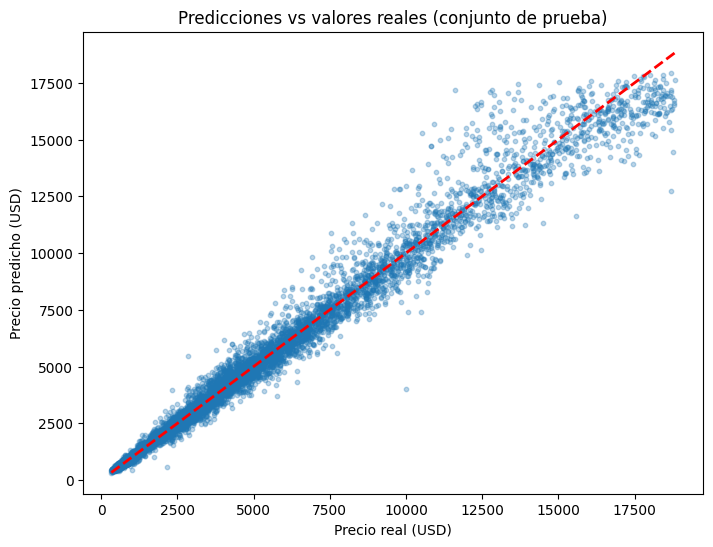

In [58]:
# Importamos las métricas de regresión que faltan
from sklearn.metrics import mean_absolute_error, r2_score

# Predicciones del modelo final sobre datos que NUNCA vio (test)
y_pred_final = modelo_final.predict(X_test)

# Calculamos las tres métricas de evaluación
rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))   # raíz del error cuadrático medio (USD)
mae = mean_absolute_error(y_test, y_pred_final)            # error absoluto medio (interpretación directa)
r2 = r2_score(y_test, y_pred_final)                        # coeficiente de determinación (varianza explicada)

print(f"RMSE: {rmse:.0f} USD")
print(f"MAE:  {mae:.0f} USD")
print(f"R²:   {r2:.4f}")

# Gráfica de dispersión: valores reales vs predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_final, alpha=0.3, s=10)         # cada punto = un diamante del test
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)  # línea ideal (predicción perfecta)
plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho (USD)')
plt.title('Predicciones vs valores reales (conjunto de prueba)')
plt.show()




### ¿Cómo interpretar la salida?

- **RMSE**: en Diamonds un RMSE ≈ 500-560 USD significa que el error típico ronda los $500 en un rango de precios de $326 a $18.823. Es un resultado excelente.
- **MAE**: "en promedio, el modelo se equivoca por ~$X" (suele ser menor que el RMSE, ~380-450 USD).
- **R²**: si es ~0.97-0.98, el modelo explica el 97-98% de la varianza del precio. Arriba de 0.7 en datos reales ya es bueno; si es menor a ~0.3, revisa features y modelos.
- **Gráfica de dispersión**: si los puntos se pegan a la línea roja diagonal, el modelo predice bien. En Diamonds verás un abanico que se abre en los precios altos (pocos diamantes caros → más error ahí).
- Compara estas métricas con la línea base del Paso 4: deberías ver una mejora (aunque modesta: con árboles ya bien configurados, la optimización suele aportar 1-3%; díselo honestamente en el informe).

---

## 12. Paso 10 — Feature Importance (importancia global)

**¿Qué pide el enunciado?** *"Use Feature Importance... para evaluar la importancia global de las features."*

### ¿Qué es y para qué sirve?

Los modelos de árboles calculan, durante el entrenamiento, cuánto reduce la **impureza** (heterogeneidad de los valores objetivo en cada nodo) cada feature cuando se usa para dividir. Esa reducción acumulada, ponderada por el número de muestras que pasan por cada nodo, es la **importancia por disminución de impureza (MDI)** y viene gratis en `feature_importances_` (lo mismo que en la Práctica 2.1).

Sirve para responder: *"¿qué variables usa más el modelo para decidir?"*

**Celda 22 — Extraer y graficar las importancias**


              Feature  Importancia
4              num__y     0.432651
0          num__carat     0.217789
18    cat__clarity_I1     0.059416
21   cat__clarity_SI2     0.043540
20   cat__clarity_SI1     0.036845
23   cat__clarity_VS2     0.027989
22   cat__clarity_VS1     0.025482
17       cat__color_J     0.024700
16       cat__color_I     0.017028
19    cat__clarity_IF     0.016790
15       cat__color_H     0.014758
24  cat__clarity_VVS1     0.012290


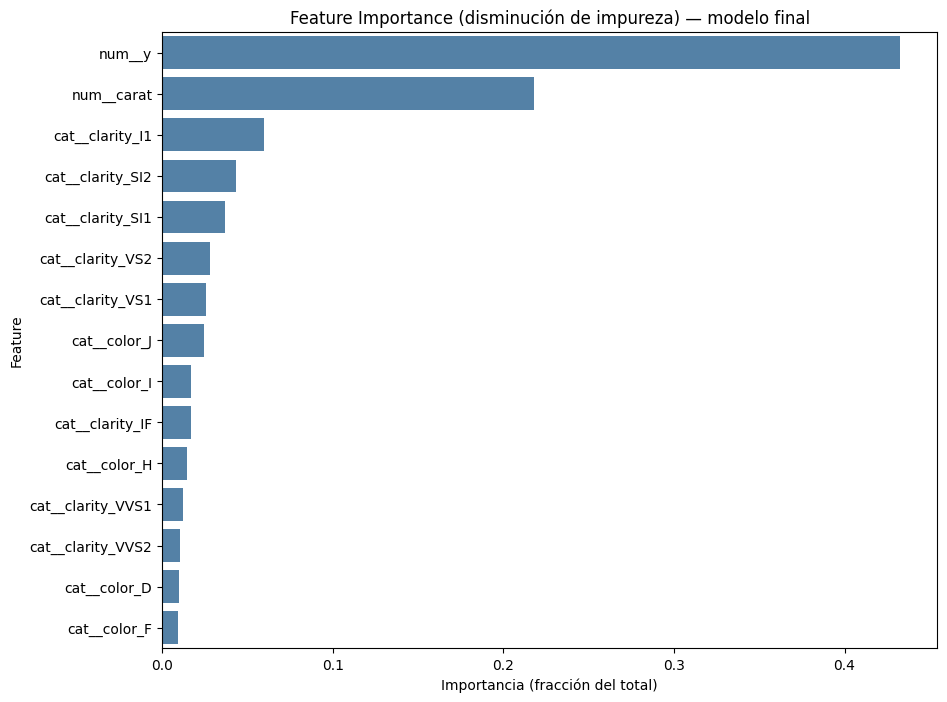

In [59]:
# Extraemos el estimador ya entrenado que vive dentro del pipeline final
modelo_entrenado = modelo_final.named_steps['modelo']

# Las importancias calculadas por el propio modelo durante el entrenamiento
importancias = modelo_entrenado.feature_importances_

# Nombres de las features tal como salen del preprocesador (mismo orden que las columnas de entrenamiento)
# OJO: las categóricas one-hot aparecen desglosadas (cat__cut_Ideal, cat__color_E, ...)
nombres = modelo_final.named_steps['preprocesador'].get_feature_names_out()

# Armamos un DataFrame ordenado de mayor a menor importancia
importancia_df = pd.DataFrame({
    'Feature': nombres,            # nombre de cada feature (pos-transformación)
    'Importancia': importancias    # su importancia MDI (suman 1 entre todas)
}).sort_values('Importancia', ascending=False)   # ordenamos de la más a la menos importante

print(importancia_df.head(12))     # top 12 features por importancia

# Gráfica de barras horizontales (top 15)
plt.figure(figsize=(10, 8))
sns.barplot(data=importancia_df.head(15), x='Importancia', y='Feature', color='steelblue')
plt.title('Feature Importance (disminución de impureza) — modelo final')
plt.xlabel('Importancia (fracción del total)')
plt.show()




### ¿Cómo interpretar la salida?

- En Diamonds, `num__carat` suele acaparar ~60-70% de la importancia: el peso del diamante es, por mucho, el mayor determinante del precio. Tiene total sentido de negocio.
- Después aparecen las categóricas one-hot (p. ej. `cat__clarity_I1`, `cat__cut_Ideal`, `cat__color_D`) y las dimensiones `num__x/y/z`. Interpreta cada columna binaria como "qué tanto pesa esa categoría en las decisiones".
- **Limitaciones del MDI que debes mencionar en tu informe**:
  1. Se calcula sobre los datos de **entrenamiento**: mide cuánto *usa* el modelo cada feature, no cuánto *ayuda* a generalizar.
  2. Favorece features con **muchos valores posibles** (alta cardinalidad) o continuas.
  3. No dice la **dirección** del efecto (si sube o baja la predicción).
  Por eso lo complementamos con las dos técnicas siguientes.

---

## Paso 11 — Permutation Importance (importancia global)

### ¿Qué es y para qué sirve?

Idea central (MDA, *Mean Decrease in Accuracy*) — es la técnica de la Práctica 2.1: si una feature es importante, **romperla** debe hacer que el modelo empeore. El procedimiento:

1. Evalúa el modelo sobre el test (score base).
2. Toma una columna y **baraja sus valores al azar** (se destruye su relación con el objetivo).
3. Vuelve a evaluar: la **caída del score** es la importancia de esa feature.
4. Repite varias veces (`n_repeats`) para tener estabilidad (promedio ± desviación).

Ventajas: es **agnóstica al modelo** (sirve para cualquier algoritmo), se mide sobre datos de **prueba** (mide valor predictivo real) y no sufre el sesgo de cardinalidad del MDI. Como el pipeline recibe las columnas originales, esta gráfica agrupa cada variable categórica completa; MDI y SHAP muestran sus categorías one-hot por separado.

**Celda 23 — Calcular y graficar la importancia por permutación**


   Feature  Importancia media     Desviación
0    carat       1.953347e+07  213249.475884
7        y       4.489435e+06   41350.125114
3  clarity       2.373024e+06   40843.971756
2    color       1.360818e+06   28651.843370
8        z       1.454113e+05    2612.013822
6        x       1.238789e+05    1734.593107
1      cut       2.941547e+04    2514.846674
4    depth       1.442746e+04    2178.137823
5    table       9.133633e+03    1693.797379


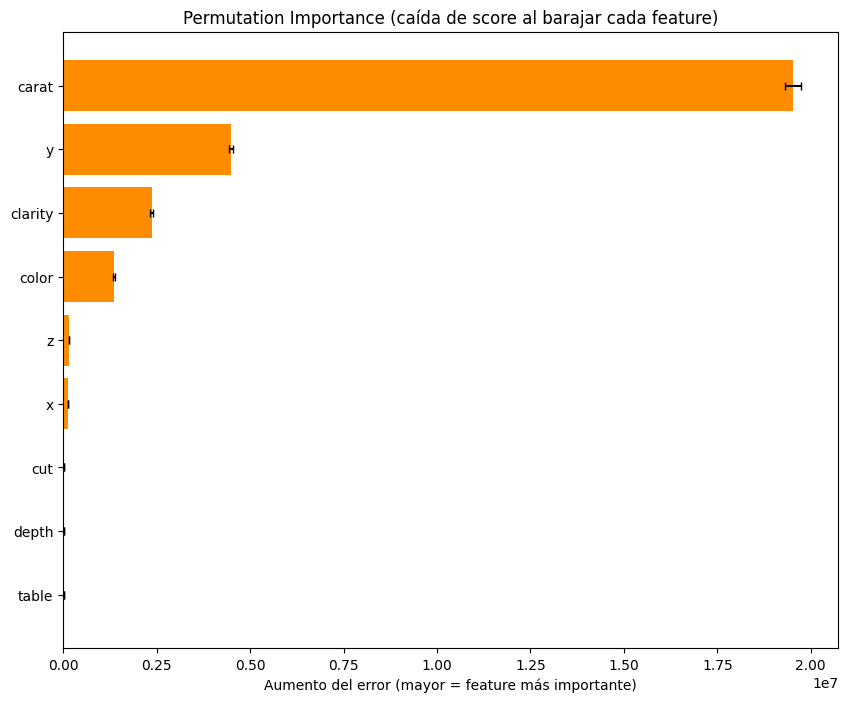

In [60]:
# Función de sklearn para importancia por permutación
from sklearn.inspection import permutation_importance

# Calculamos la importancia permutando cada columna 15 veces
resultado_pi = permutation_importance(
    modelo_final,                            # el pipeline completo (se encarga de transformar X_test)
    X_test,                                  # datos de PRUEBA sin transformar
    y_test,                                  # valores reales del test
    n_repeats=15,                            # repeticiones por columna (más = más estable)
    random_state=42,                         # barajado reproducible
    scoring='neg_mean_squared_error',        # métrica: cuánto EMPEORA el MSE al barajar
    n_jobs=-1                                # paraleliza las repeticiones
)

# Armamos DataFrame con promedio y desviación estándar de la caída de score
pi_df = pd.DataFrame({
    'Feature': X_test.columns,                       # PI recibe las columnas originales del pipeline (no las one-hot)
    'Importancia media': resultado_pi.importances_mean,   # caída PROMEDIO del score
    'Desviación': resultado_pi.importances_std            # variabilidad entre repeticiones
}).sort_values('Importancia media', ascending=False)      # ordenamos de mayor a menor

print(pi_df.head(12))     # top 12

# Gráfica de barras horizontales (top 15) con barras de error (una desviación estándar)
plt.figure(figsize=(10, 8))
top_pi = pi_df.head(15)
plt.barh(top_pi['Feature'], top_pi['Importancia media'],
         xerr=top_pi['Desviación'],               # barras de error = incertidumbre de la estimación
         color='darkorange', capsize=3)           # capsize = topes en los extremos de las barras de error
plt.gca().invert_yaxis()                         # invertimos el eje para ver la más importante arriba
plt.title('Permutation Importance (caída de score al barajar cada feature)')
plt.xlabel('Aumento del error (mayor = feature más importante)')
plt.show()




### ¿Cómo interpretar la salida?

- Cuanto mayor la caída del score, más depende el modelo de esa feature. En Diamonds, `num__carat` vuelve a encabezar.
- **Fenómeno interesante con features correlacionadas** (¡menciónalo en tu informe!): como `carat`, `x`, `y` y `z` están fuertemente correlacionadas, al barajar solo `carat` el modelo puede "recuperarse" usando las dimensiones. Por eso la importancia de permutación de `carat` se ve **menor** que su importancia MDI. La lección: con multicolinealidad, la importancia individual se reparte entre las features redundantes; es una limitación conocida de la permutación (y de casi todas las técnicas de importancia).
- **Desviación grande** = la importancia varía mucho entre repeticiones (menos confiable). Regla práctica: si `importancia media < 2 × desviación`, duda de su relevancia.
- Si una feature sale con importancia ~0 (o negativa), el modelo no la necesita para predecir.
- Compara el **ranking** con el MDI del paso anterior: si coinciden en el top, tienes evidencia sólida; si difieren, explica por qué (multicolinealidad o sesgo de cardinalidad del MDI).

---

## Paso 12 — SHAP Values (importancia global)


### ¿Qué es y para qué sirve?

SHAP (Lundberg & Lee, 2017) calcula la contribución **aditiva y justa** de cada feature a cada predicción, usando valores de Shapley de la teoría de juegos cooperativos: reparte la "ganancia" (la diferencia entre la predicción y el valor base) entre las features según su aporte marginal en todas las combinaciones posibles. Propiedades clave:

- **Aditividad**: `predicción = valor_base + Σ contribuciones` (exacta).
- **Consistencia**: si el modelo depende más de una feature, su contribución SHAP no puede disminuir.
- Para modelos de árboles, el explicador calcula los valores SHAP **exactos y rápido** (sin simulaciones).

Es **exactamente la técnica de la Práctica 2.2**, con la misma API moderna: `shap.Explainer(model, X_train)`, `explainer(X)`, `shap.plots.bar`, `shap.plots.beeswarm` y `shap.plots.waterfall`.

**Celda 24 — Calcular SHAP values globales**


In [61]:
# Importamos SHAP (librería de IA explicativa, la misma de la Práctica 2.2)
import shap

# Preparamos los datos de test pasados por el MISMO preprocesador del modelo final
X_test_transformado = modelo_final.named_steps['preprocesador'].transform(X_test)
X_test_transformado = pd.DataFrame(X_test_transformado, columns=nombres)  # DataFrame con nombres
X_test_transformado = X_test_transformado.sample(n=min(750, len(X_test_transformado)), random_state=42)  # muestra representativa para explicar

# Datos de ENTRENAMIENTO transformados: sirven como "fondo" (background) para calcular el valor base
X_train_transformado = pd.DataFrame(
    modelo_final.named_steps['preprocesador'].transform(X_train),
    columns=nombres
).sample(n=min(100, len(X_train)), random_state=42)  # fondo pequeño para ejecución eficiente

# Creamos el explicador pasando el modelo entrenado y el fondo de datos (API de la Práctica 2.2)
explainer = shap.Explainer(modelo_entrenado, X_train_transformado)

# Calculamos los valores SHAP para todo el conjunto de prueba
explicacion = explainer(X_test_transformado)

# verificamos la forma: (n_muestras_test, n_features)
print('Forma de los valores SHAP:', explicacion.values.shape)


 99%|===================| 739/750 [00:19<00:00]       

Forma de los valores SHAP: (750, 26)




**Celda 25 — Gráfica global 1: barras (importancia global promedio)**


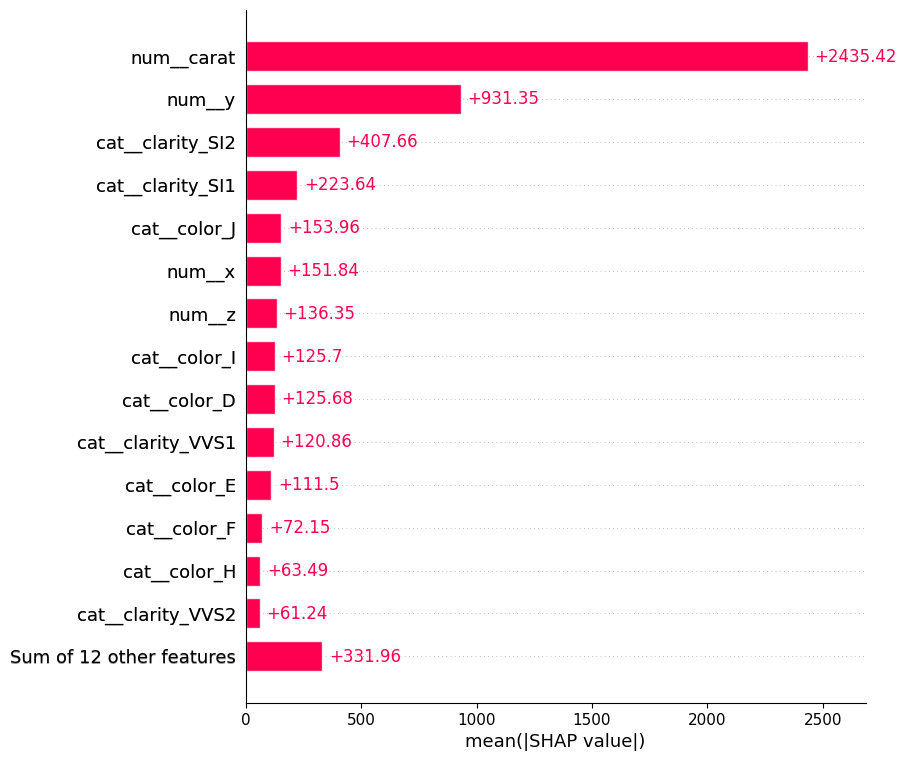

In [62]:
# Gráfica de barras: media del valor ABSOLUTO de los SHAP values por feature
# (es el análogo de SHAP a las importancias de los pasos anteriores; igual que la Práctica 2.2)
shap.plots.bar(explicacion, max_display=15)




**Celda 26 — Gráfica global 2: beeswarm (enjambre)**


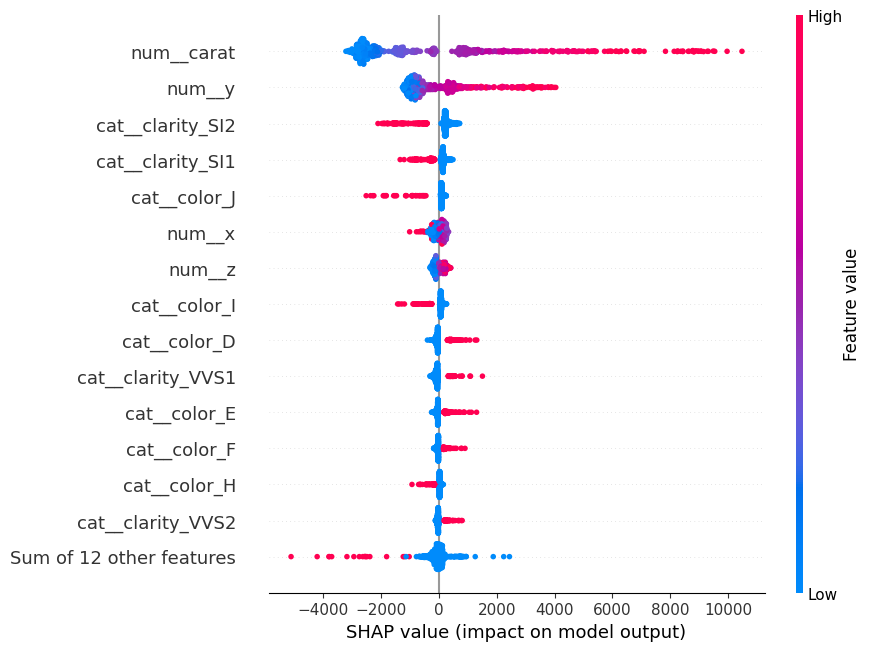

In [63]:
# Beeswarm: cada PUNTO es una muestra; su posición X es el impacto SHAP en la predicción
# y su COLOR es el valor de la feature (rojo = alto, azul = bajo)
shap.plots.beeswarm(explicacion, max_display=15)   # max_display limita las features mostradas




### ¿Cómo interpretar la salida?

**Barras**: promedio de |SHAP| por feature. Es la "tabla de posiciones" global: compárala con MDI y Permutation. Si las tres técnicas coinciden en el top (`num__carat` primero, seguido de las categorías de `clarity`, `cut` y `color`), tu conclusión es robusta.

**Beeswarm**:

- El eje Y ordena las features por importancia global (la más arriba = más importante).
- Cada punto es una **muestra del test**: si está a la derecha del cero, esa feature **empujó esa predicción hacia arriba**; a la izquierda, hacia abajo.
- El color indica el **valor de la feature**: en Diamonds, los puntos rojos de `num__carat` (diamantes pesados) están muy a la derecha → a mayor peso, mayor precio predicho. Confirma una relación **positiva y consistente**.
- Para las categóricas one-hot (0/1), el "rojo" significa presencia de la categoría: p. ej. `cat__clarity_I1` rojo a la izquierda → un diamante de pureza I1 (la peor) baja el precio; `cat__cut_Ideal` rojo a la derecha → el corte Ideal lo sube. Así SHAP te dice la **dirección** del efecto, cosa que MDI y Permutation no hacen.

---

## Paso 13 — Predicción nueva y explicación LOCAL con SHAP


### ¿Qué es y para qué sirve?

Hasta ahora explicamos el modelo **en general**. Ahora tomamos **un solo diamante nuevo** (que el modelo nunca vio), predecimos su precio y desglosamos **por qué** el modelo dijo ese número: qué features empujaron el precio hacia arriba y cuáles hacia abajo. Esto es la **explicación local** (el waterfall de la Práctica 2.2), y es lo que usarías en producción para justificar una predicción ante un usuario.

**Celda 27 — Crear y predecir un diamante nuevo**


In [64]:
# Creamos UNA nueva observación: un diamante de 1 quilate, corte Ideal, color G, pureza SI1
# Valores en las unidades originales del dataset (mismo orden de columnas)
nuevo_diamante = pd.DataFrame({
    'carat':   [1.0],        # peso en quilates
    'cut':     ['Ideal'],    # calidad del corte (categórica)
    'color':   ['G'],        # grado de color (categórica)
    'clarity': ['SI1'],      # pureza (categórica)
    'depth':   [61.5],       # profundidad total (%)
    'table':   [57.0],       # ancho de la mesa (%)
    'x':       [6.4],        # largo (mm)
    'y':       [6.4],        # ancho (mm)
    'z':       [3.9],        # alto (mm)
})

# El modelo final predice el precio del diamante
prediccion_nueva = modelo_final.predict(nuevo_diamante)

print(f"Precio predicho: ${prediccion_nueva[0]:,.0f} USD")


Precio predicho: $5,095 USD




**Celda 28 — Explicación local con SHAP (waterfall)**


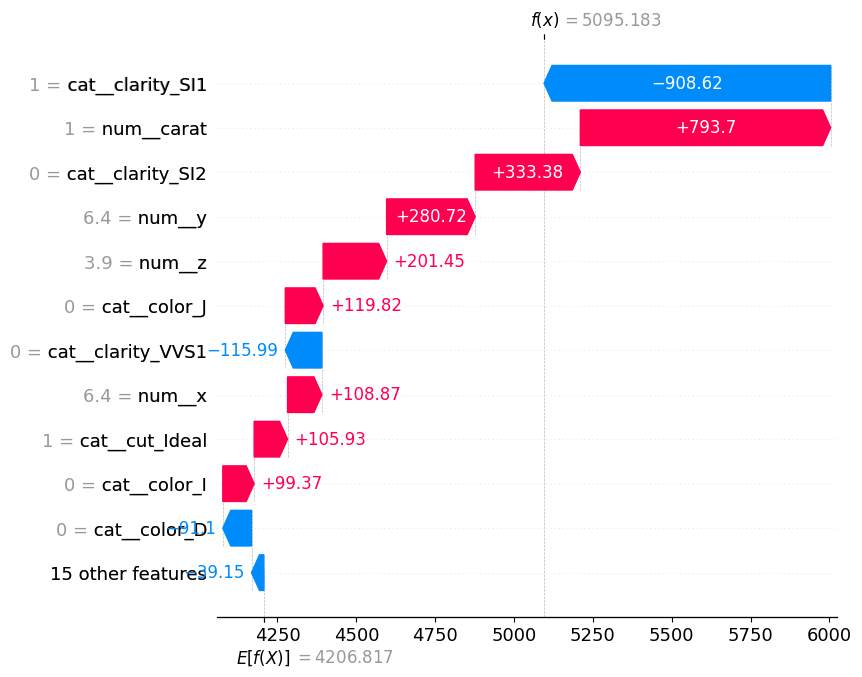

In [65]:
# Transformamos el diamante nuevo con el preprocesador del modelo final (imputación + one-hot, sin escala)
X_nueva_transformada = pd.DataFrame(
    modelo_final.named_steps['preprocesador'].transform(nuevo_diamante),
    columns=nombres
)

# Calculamos los valores SHAP de esa ÚNICA predicción
explicacion_local = explainer(X_nueva_transformada)

# Waterfall: muestra cómo cada feature empujó la predicción desde el valor base
# hasta el valor final predicho (rojo = empuja hacia arriba, azul = hacia abajo)
shap.plots.waterfall(explicacion_local[0], max_display=12)




**Celda 29 — Verificación numérica de la aditividad de SHAP**


In [66]:
# Comprobamos la identidad fundamental de SHAP: predicción = base + suma de contribuciones
base = float(np.ravel(explicacion_local.base_values)[0])   # valor base = predicción esperada del modelo
contribuciones = explicacion_local.values[0]               # contribuciones de cada feature

print(f"Valor base (predicción esperada del modelo): ${base:,.0f}")
print(f"Suma de contribuciones SHAP:                 ${contribuciones.sum():,.0f}")
print(f"Predicción reconstruida (base + suma):       ${base + contribuciones.sum():,.0f}")
print(f"Predicción real del modelo:                  ${prediccion_nueva[0]:,.0f}")


Valor base (predicción esperada del modelo): $4,207
Suma de contribuciones SHAP:                 $888
Predicción reconstruida (base + suma):       $5,095
Predicción real del modelo:                  $5,095




### ¿Cómo interpretar la salida?

**Waterfall**: se lee de abajo hacia arriba:

- `E[f(x)]` (base): lo que el modelo predeciría "sin saber nada" (la media de sus predicciones de entrenamiento, ≈ $3.930 en Diamonds).
- Cada fila es una feature: la flecha **roja** (derecha) suma al precio, la **azul** (izquierda) resta. El número de la derecha es el valor de la feature (en unidades originales, porque quitamos el escalador).
- `f(x)` arriba: la predicción final = base + todas las flechas.

Para el diamante de ejemplo (1 ct, Ideal, G, SI1), espera una historia como esta:

- `num__carat = 1.0` (por encima de la media de 0.8): flecha roja grande → +$1.500 aprox.
- `cat__cut_Ideal = 1`: flecha roja pequeña → el corte Ideal suma (premium de marca).
- `cat__clarity_SI1 = 1`: flecha azul → la pureza SI1 (media-baja) resta un poco frente a claridades superiores.
- `cat__color_G = 1`: flecha azul pequeña → el color G resta frente a los D/E/F más raros.
- `num__x/y/z`: contribuciones pequeñas (la información de tamaño ya la aporta `carat`).

La **celda 29** debe dar dos números prácticamente idénticos en las dos últimas líneas: esa es la prueba matemática de que SHAP descompone la predicción de forma exacta (pequeñas diferencias de 1e-8 son solo error numérico de punto flotante).

> **Nota**: `force_plot` (la gráfica antigua de SHAP) está deprecada en versiones recientes; el waterfall es su reemplazo oficial (es el que usaste en la Práctica 2.2).

---

## 16. Conclusiones (lo que debes redactar en tu informe)

Tu informe debe responder, con tus propios números y gráficas:

1. **Dataset**: cuál elegiste, de dónde (cita la fuente) y por qué cumple "diferente a los de las prácticas" (las prácticas usaron Adult, California Housing, Diabetes, Breast Cancer, series sintéticas e insurance).
2. **EDA**: hallazgos principales de tu `AutoEDA` reutilizada (faltantes, outliers, sesgo, multicolinealidad VIF en `carat`/`x`/`y`/`z`, correlaciones con el objetivo) y las decisiones que tomaste a partir de ellos (p. ej. "no elimino outliers porque los árboles son robustos").
3. **Preprocesamiento**: qué hiciste (imputación, escalado, OneHot) y por qué, y cómo el Pipeline evita la fuga de datos.
4. **Métodos de búsqueda**: tabla comparativa de los experimentos. ¿Qué método logró el mejor poder predictivo (score)? ¿Cuánto tardó cada uno? ¿Cuál ofrece la mejor relación calidad/tiempo y por qué? (fundamenta con los conceptos: explosión combinatoria de Grid, eficiencia de muestreo de Random, modelo sustituto de Bayesiana).
5. **Modelo final**: qué modelo ganó, con qué hiperparámetros, y sus métricas finales (RMSE, MAE, R²) vs la línea base.
6. **Importancia global**: qué features son las más importantes según MDI, Permutation y SHAP. ¿Coinciden los rankings? ¿Tienen sentido de negocio (el peso del diamante manda en el precio)? Explica el efecto de la multicolinealidad en la Permutation Importance.
7. **Explicación local**: muestra el waterfall de tu predicción nueva y narra la historia ("el modelo predice $X porque carat=1.0 sumó +..., la pureza SI1 restó -...").
8. **Limitaciones**: sesgos del MDI, dependencia del hardware en los tiempos, error mayor en diamantes caros (pocos ejemplos), etc.

---


## Referencias

- Pace, R. K., & Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters*, 33(3), 291-297. (Dataset California Housing, usado en las prácticas 2.1 y 2.2)
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281-305.
- Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. *NeurIPS 24*. (TPE)
- Lundberg, S. M., & Lee, S. I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*. (SHAP)
- Documentación: scikit-learn (https://scikit-learn.org), XGBoost (https://xgboost.readthedocs.io), SHAP (https://shap.readthedocs.io), Optuna (https://optuna.org), scikit-optimize (https://scikit-optimize.github.io)
- Prácticas de clase del repositorio del curso: `Unidad 1` (Prácticas 1, 2.1, 2.2, 3), `Unidad 2` (Prácticas 4, 5, 6A, 6B) y `Actividad Integradora 1` (`herramientas_eda.py`).
